##  LECTURE3 : Vision - Convoultional Neural Network
## Image Classification 웹앱 만들기 프로젝트1:: teachable machine + netlify


- 1교시: Vanilla BP
- 2교시: Torch.nn
- 3교시: CNN
- 4교시: Siamesse network
- 5교시: 티쳐블머신 받기 + 배포
---


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

## [1교시] 복습


#### Linear regression

- Example
    - x: independent variable
        - Weight
    - y: dependent variable
        - Height
- $y=\alpha x + \beta$


In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
# Creates 50 random x and y numbers
np.random.seed(1)
n = 50
x = np.random.randn(n)
y = x * np.random.randn(n)

In [4]:
# Makes the dots colorful
colors = np.random.rand(n)

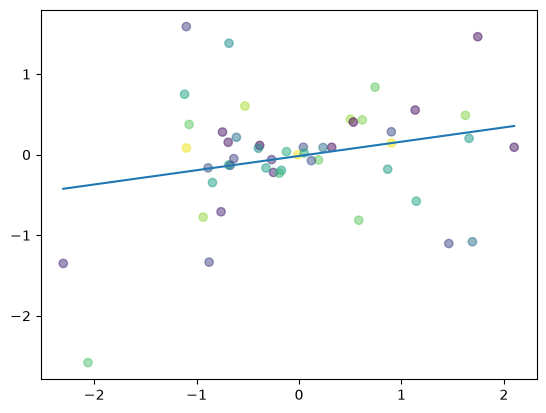

In [5]:
# Plots best-fit line via polyfit
plt.plot(np.unique(x), np.poly1d(np.polyfit(x, y, 1))(np.unique(x)))

# Plots the random x and y data points we created
# Interestingly, alpha makes it more aesthetically pleasing
plt.scatter(x, y, c=colors, alpha=0.5)
plt.show()

- 목표 = "점의 분포를 가장 잘 설명하는 선을 찾는것"  
> $y = \alpha x + \beta$

- Adjusting
    - Coefficient: $\alpha$
    - Bias/intercept: $\beta$

예를 들어.
- Coefficient: $\alpha = 2$
- Bias/intercept: $\beta = 1$
- Equation: $y = 2x + 1$


**Create a list of values from 0 to 11**

In [6]:
x_values = [i for i in range(11)]

In [7]:
x_values

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

**Convert list of numbers to numpy array**

In [8]:
# Convert to numpy
x_train = np.array(x_values, dtype=np.float32)
x_train.shape

(11,)

**Convert to 2-dimensional array**

데이터 차원이 1차인것 vs 2차인데 한 차원의 길이가 1인것?

ex. torch.unsqueeze()

import torch

x = torch.rand(3, 20, 128).  
x = x.unsqueeze(dim=1)
#[3, 20, 128] -> [3, 1, 20, 128]

In [9]:
# IMPORTANT: 2D required
x_train = x_train.reshape(-1, 1)
x_train.shape

(11, 1)

**Create list of y values and Convert to numpy array**


    
$y = 2x + 1$

In [10]:
y_values = [2*i + 1 for i in x_values]

# y_values = []
# for i in x_values:
#     result = 2*i + 1
#     y_values.append(result)

In [11]:
y_values

[1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21]

In [12]:
y_train = np.array(y_values, dtype=np.float32)
y_train.shape

(11,)

In [13]:
# IMPORTANT: 2D required
y_train = y_train.reshape(-1, 1)
y_train.shape

(11, 1)

**Create Model**

1. Linear model
    - True Equation:  y = 2x + 1
2. Forward
    - Example
        - Input: x = 1
        - Output y = ?

In [14]:
# Create class
class LinearRegressionModel(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, output_dim)

    def forward(self, x):
        out = self.linear(x)
        return out

**Instantiate Model Class**

- input: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
- desired output: [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21]

In [15]:
input_dim = 1
output_dim = 1

model = LinearRegressionModel(input_dim, output_dim)

**Instantiate Loss Class**
- MSE Loss: Mean Squared Error
- $MSE = \frac{1}{n} \sum_{i=1}^n(\hat y_i - y_i)$
    - $\hat y$: prediction
    - $y$: true value

In [16]:
criterion = nn.MSELoss()

**Instantiate Optimizer Class**

- Simplified equation
    - W_new = W_old - learning_rate * gradient
        - W_new: 업데이트된 가중치 (our variables)
        - learning_rate: 학습률(how fast we want to learn)
        - gradient: parameters' gradients
- Even simplier equation
    - `parameters = parameters - learning_rate * parameters_gradients`
        - parameters: w(weight) and b(bias) in $y = wx + b
        - desired parameters: w = 2 and b = 1 in  y = 2x + 1

In [17]:
learning_rate = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

**Train Model**

In [18]:
epochs = 3000
for epoch in range(epochs):
    # Convert numpy array to torch Variable
    inputs = torch.from_numpy(x_train)
    labels = torch.from_numpy(y_train)

    # Clear gradients w.r.t. parameters
    optimizer.zero_grad()

    # Forward to get output
    outputs = model(inputs)

    # Calculate Loss
    loss = criterion(outputs, labels)

    # Getting gradients w.r.t. parameters
    loss.backward()

    # Updating parameters
    optimizer.step()

    print('epoch {}, loss {}'.format(epoch, loss.item()))

epoch 0, loss 220.59584045410156
epoch 1, loss 18.575340270996094
epoch 2, loss 2.0906691551208496
epoch 3, loss 0.7396390438079834
epoch 4, loss 0.6230841875076294
epoch 5, loss 0.6072931289672852
epoch 6, loss 0.5997914671897888
epoch 7, loss 0.5930345058441162
epoch 8, loss 0.5864078998565674
epoch 9, loss 0.5798590183258057
epoch 10, loss 0.5733837485313416
epoch 11, loss 0.5669809579849243
epoch 12, loss 0.5606494545936584
epoch 13, loss 0.5543888211250305
epoch 14, loss 0.5481982827186584
epoch 15, loss 0.542076051235199
epoch 16, loss 0.5360232591629028
epoch 17, loss 0.5300373435020447
epoch 18, loss 0.5241186618804932
epoch 19, loss 0.5182662010192871
epoch 20, loss 0.5124784111976624
epoch 21, loss 0.5067557692527771
epoch 22, loss 0.5010966658592224
epoch 23, loss 0.4955013394355774
epoch 24, loss 0.48996812105178833
epoch 25, loss 0.4844965934753418
epoch 26, loss 0.4790862202644348
epoch 27, loss 0.4737362563610077
epoch 28, loss 0.4684462249279022
epoch 29, loss 0.4632153

**Looking at predicted values**

In [19]:
# Purely inference
predicted = model(torch.from_numpy(x_train)).data.numpy()

In [20]:
predicted

array([[ 0.99999267],
       [ 2.9999938 ],
       [ 4.999995  ],
       [ 6.9999967 ],
       [ 8.999997  ],
       [10.999998  ],
       [13.        ],
       [15.000001  ],
       [17.000002  ],
       [19.000004  ],
       [21.000004  ]], dtype=float32)

**Looking at training values**

These are the true values, you can see how it's able to predict similar values.

In [21]:
# y = 2x + 1
y_train

array([[ 1.],
       [ 3.],
       [ 5.],
       [ 7.],
       [ 9.],
       [11.],
       [13.],
       [15.],
       [17.],
       [19.],
       [21.]], dtype=float32)

**Plot of predicted and actual values**

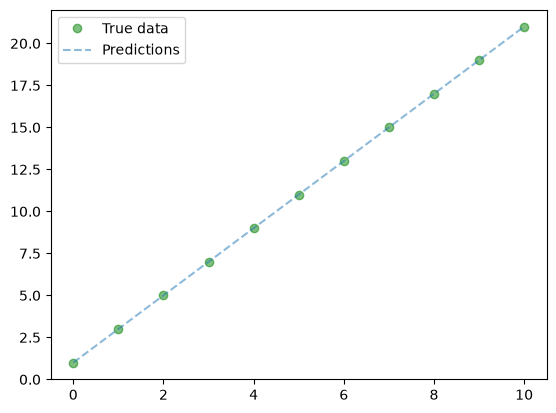

In [22]:
# Clear figure
plt.clf()

# Get predictions
predicted = model(torch.from_numpy(x_train)).data.numpy()

# Plot true data
plt.plot(x_train, y_train, 'go', label='True data', alpha=0.5)

# Plot predictions
plt.plot(x_train, predicted, '--', label='Predictions', alpha=0.5)

# Legend and plot
plt.legend(loc='best')
plt.show()

**Save Model**

In [23]:
save_model = False
if save_model is True:
    # Saves only parameters
    # alpha & beta
    torch.save(model.state_dict(), 'awesome_model.pkl')

**Load Model**

In [24]:
load_model = False
if load_model is True:
    model.load_state_dict(torch.load('awesome_model.pkl'))


- x[공부한 시간, 자는 시간] in X
- y는 성적
- 목표는 x->y :: 관계를 학습하는것
- 문제: Xp는 과연 성적을 얼마로 생각할까?

출처: https://medium.com/dair-ai/a-simple-neural-network-from-scratch-with-pytorch-and-google-colab-c7f3830618e0


In [25]:
X = torch.tensor(([2, 8], [1, 9], [3, 7]), dtype=torch.float) # 3 X 2 tensor
y = torch.tensor(([86], [60], [95]), dtype=torch.float) # 3 X 1 tensor
Xp = torch.tensor(([2.5, 8]), dtype=torch.float) # 1 X 2 tensor

print(X, X.size())
print(y, y.size())

# Q. scale units: scale이 효과가 있을까요?
SCALE = False
# SCALE = True
if SCALE:
    X_max, _ = torch.max(X, 0)
    X = torch.div(X, X_max)
    Xp = torch.div(Xp, X_max)
    y = y / 100  # max test score is 100

tensor([[2., 8.],
        [1., 9.],
        [3., 7.]]) torch.Size([3, 2])
tensor([[86.],
        [60.],
        [95.]]) torch.Size([3, 1])


In [26]:
class Neural_Network(nn.Module):
    def __init__(self, ):
        super().__init__()
        # parameters
        # TODO: parameters can be parameterized instead of declaring them here
        self.inputSize = 2
        self.outputSize = 1
        self.hiddenSize = 3

        # weights
        self.W1 = torch.randn(self.inputSize, self.hiddenSize) # 2 X 3 tensor
        self.W2 = torch.randn(self.hiddenSize, self.outputSize) # 3 X 1 tensor

    def forward(self, X):
        self.z = torch.matmul(X, self.W1) # 3 X 3 ".dot" does not broadcast in PyTorch
        self.z2 = self.sigmoid(self.z) # activation function
        self.z3 = torch.matmul(self.z2, self.W2)
        o = self.sigmoid(self.z3) # final activation function
        return o

    def sigmoid(self, s):
        return 1 / (1 + torch.exp(-s))

    def sigmoidPrime(self, s):
        # derivative of sigmoid
        return s * (1 - s)

    def backward(self, X, y, o):
        self.o_error = y - o # error in output
        self.o_delta = self.o_error * self.sigmoidPrime(o) # derivative of sig to error
        self.z2_error = torch.matmul(self.o_delta, torch.t(self.W2))
        self.z2_delta = self.z2_error * self.sigmoidPrime(self.z2)
        self.W1 += torch.matmul(torch.t(X), self.z2_delta)
        self.W2 += torch.matmul(torch.t(self.z2), self.o_delta)

    def train(self, X, y):
        # forward + backward pass for training
        o = self.forward(X)
        self.backward(X, y, o)

    def saveWeights(self, model):
        # we will use the PyTorch internal storage functions
        torch.save(model, "NN")
        # you can reload model with all the weights and so forth with:
        # torch.load("NN")

    def predict(self):
        print ("Predicted data based on trained weights: ")
        print ("Input (scaled): \n" + str(Xp))
        print ("Output: \n" + str(self.forward(Xp)))

In [27]:
NN = Neural_Network()
for i in range(1000):  # trains the NN 1,000 times
    print ("#" + str(i) + " Loss: " + str(torch.mean((y - NN(X))**2).detach().item()))  # mean sum squared loss
    NN.train(X, y)
NN.saveWeights(NN)
NN.predict()


#0 Loss: 6572.88427734375
#1 Loss: 6514.0
#2 Loss: 6514.0
#3 Loss: 6514.0
#4 Loss: 6514.0
#5 Loss: 6514.0
#6 Loss: 6514.0
#7 Loss: 6514.0
#8 Loss: 6514.0
#9 Loss: 6514.0
#10 Loss: 6514.0
#11 Loss: 6514.0
#12 Loss: 6514.0
#13 Loss: 6514.0
#14 Loss: 6514.0
#15 Loss: 6514.0
#16 Loss: 6514.0
#17 Loss: 6514.0
#18 Loss: 6514.0
#19 Loss: 6514.0
#20 Loss: 6514.0
#21 Loss: 6514.0
#22 Loss: 6514.0
#23 Loss: 6514.0
#24 Loss: 6514.0
#25 Loss: 6514.0
#26 Loss: 6514.0
#27 Loss: 6514.0
#28 Loss: 6514.0
#29 Loss: 6514.0
#30 Loss: 6514.0
#31 Loss: 6514.0
#32 Loss: 6514.0
#33 Loss: 6514.0
#34 Loss: 6514.0
#35 Loss: 6514.0
#36 Loss: 6514.0
#37 Loss: 6514.0
#38 Loss: 6514.0
#39 Loss: 6514.0
#40 Loss: 6514.0
#41 Loss: 6514.0
#42 Loss: 6514.0
#43 Loss: 6514.0
#44 Loss: 6514.0
#45 Loss: 6514.0
#46 Loss: 6514.0
#47 Loss: 6514.0
#48 Loss: 6514.0
#49 Loss: 6514.0
#50 Loss: 6514.0
#51 Loss: 6514.0
#52 Loss: 6514.0
#53 Loss: 6514.0
#54 Loss: 6514.0
#55 Loss: 6514.0
#56 Loss: 6514.0
#57 Loss: 6514.0
#58 Loss: 6514

SCALE = True 일시
```
#0 Loss: 0.04818464443087578
#1 Loss: 0.0437721349298954
#2 Loss: 0.040442898869514465
#3 Loss: 0.037896912544965744
#4 Loss: 0.03592438995838165
#5 Loss: 0.034376826137304306
#6 Loss: 0.03314799442887306
#7 Loss: 0.0321609228849411
#8 Loss: 0.03135917708277702
#9 Loss: 0.030700959265232086
#10 Loss: 0.030154868960380554
#11 Loss: 0.029697170481085777
#12 Loss: 0.029309729114174843
#13 Loss: 0.02897849678993225
#14 Loss: 0.028692573308944702
#15 Loss: 0.02844342030584812
#16 Loss: 0.028224261477589607
#17 Loss: 0.02802971564233303
#18 Loss: 0.027855491265654564
#19 Loss: 0.027698099613189697
#20 Loss: 0.027554774656891823
#21 Loss: 0.027423208579421043
#22 Loss: 0.02730151265859604
#23 Loss: 0.027188196778297424
#24 Loss: 0.027081971988081932
...
Input (scaled): 
tensor([0.8333, 0.8889])
Output: 
tensor([0.8974])
```

### Vanilla BackPropagation

MNIST->MLP -> classification : 좀 더 기본적으로 살펴보자


참고: https://colab.research.google.com/github/AmanDaVinci/DeepOrigins/blob/master/notebooks/03_Neural-Network-Backpropagation.ipynb#scrollTo=uoVAeRftTHfX

In [28]:
import torch
from torchvision.datasets import MNIST

import matplotlib.pyplot as plt
%matplotlib inline

**Load Data**

In [29]:
dataset = MNIST(root="../data/",download=True)

In [30]:
x, y = dataset.data.float(), dataset.targets
x_train, x_test = x[:50000], x[50000:]
y_train, y_test = y[:50000], y[50000:]

x_train.shape, x_test.shape

(torch.Size([50000, 28, 28]), torch.Size([10000, 28, 28]))

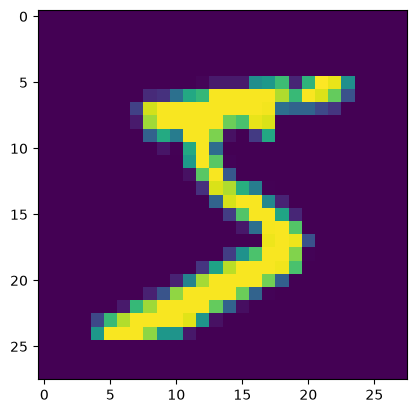

In [31]:
plt.imshow(x_train[0])

**Flatten**

In [32]:
x_train = x_train.reshape(x_train.shape[0],x_train.shape[1]*x_train.shape[2])
x_test = x_test.reshape(x_test.shape[0],x_test.shape[1]*x_test.shape[2])

In [33]:
n, m = x_train.shape
c = (y_train.max() - y_train.min()).item()
n, m, c

(50000, 784, 9)

**Normalize Data**

In [34]:
def normalize(x, mean, std): return (x-mean)/std

In [35]:
train_mean = x_train.mean()
train_std = x_train.std()

In [36]:
x_train = normalize(x_train, train_mean, train_std)
x_test = normalize(x_test, train_mean, train_std)

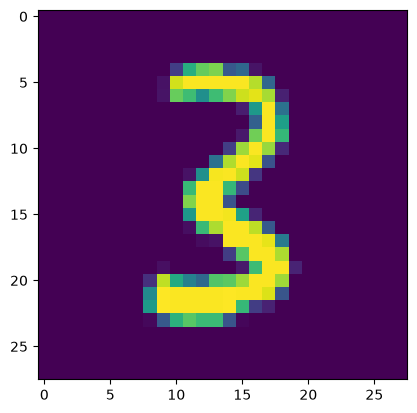

In [37]:
plt.imshow(x_test[0].view(28,28))

**Backpropagation from scratch**

In [38]:
class Layer():
    '''Abstract Layer class like PyTorch's nn.Module'''

    def __call__(self, *args):
        self.args = args
        self.y = self.forward(*self.args)
        return self.y

    def __repr__(self):
        raise NotImplementedError("__repr__ method not implemented")

    def forward(self, *args):
        raise NotImplementedError("forward method not implemented")

    def backward(self):
        raise NotImplementedError("backward method not implemented")

In [39]:
class MyLinear():
    '''Affine layer with weight and bias initialized using Kaiming initialization'''
    def __init__(self, in_size, out_size):
        self.weight = torch.randn(in_size, out_size) * ((2/in_size)**0.5)
        self.bias = torch.zeros(out_size)

    def __repr__(self):
        return f"(Linear: in={self.weight.shape[0]} out={self.weight.shape[1]})"

    def forward(self, x):
        self.x = x
        self.y = self.x@self.weight + self.bias
        return self.y

    def backward(self):
        self.weight.g = self.x.t() @ self.y.g
        self.bias.g = self.y.g
        self.x.g = self.y.g @ self.weight.t()

In [40]:
class MyReLU():
    '''Rectified Linear Unit Layer'''

    def __init__(self, shift=0.):
        self.shift = shift

    def __repr__(self):
        return f"(ReLU: shift={self.shift})"

    def forward(self, x):
        self.x = x
        self.y = self.x.clamp_min(0.) - self.shift
        return self.y

    def backward(self):
        self.x.g = self.y.g * (self.x>0).float()

In [41]:
class MyMSE():
    '''Mean Squared Error Layer'''

    def __repr__(self):
        return "Loss: Mean Squared Error"

    def forward(self, y_pred, y_true):
        self.x1 = y_pred
        self.x2 = y_true
        self.y = (self.x1-self.x2).pow(2).mean()
        return self.y

    def backward(self):
        self.x1.g = 2 * (self.x1-self.x2) / self.x1.shape[0]

In [42]:
import math
class FeedForwardNN():
    '''Feedforward neural network'''

    def __init__(self, x_dim, y_dim, n_layers):
        # get an exponentially spaced array of layer dimensions
        def _exp(pos):
            return math.ceil(x_dim * (y_dim/x_dim)**pos)
        layer_dims  = [_exp(pos/n_layers) for pos in range(0, n_layers+1)]
        # construct the list of layers
        self.layers = []
        for i in range(n_layers):
            in_dim, out_dim = layer_dims[i], layer_dims[i+1]
            self.layers.append(MyLinear(in_dim, out_dim))
            self.layers.append(MyReLU())
        self.loss = MyMSE()

    def __repr__(self):
        model_str = "\n".join(l.__repr__() for l in self.layers)
        model_str += "\n" + self.loss.__repr__()
        return model_str

    def forward(self, x):
        for l in self.layers:
            x = l.forward(x)
        return x

    def backward(self):
        self.loss.backward()
        for layer in reversed(self.layers):
            layer.backward()

In [43]:
model = FeedForwardNN(x_dim=784, y_dim=1, n_layers=5)
model

(Linear: in=784 out=207)
(ReLU: shift=0.0)
(Linear: in=207 out=55)
(ReLU: shift=0.0)
(Linear: in=55 out=15)
(ReLU: shift=0.0)
(Linear: in=15 out=4)
(ReLU: shift=0.0)
(Linear: in=4 out=1)
(ReLU: shift=0.0)
Loss: Mean Squared Error

In [44]:
y_pred = model.forward(x_train)
loss = model.loss.forward(y_pred.float(), y_train.unsqueeze(-1).float())
model.backward()

만약 이걸 torch로 만든다면?

```
class TorchModel(nn.Module):
    
    def __init__(self, x_dim, h_dim, y_dim):
        super().__init__()
        self.layers = [nn.Linear(x_dim, h_dim),
                       nn.ReLU(),
                       nn.Linear(h_dim,y_dim)]
        self.loss = nn.MSELoss()

    def forward(self, x):
        for l in self.layers:
            x = l(x)
        return x

torch_model = TorchModel(784, 400, 1)
```



### 처음부터 만들어보자
ref: https://colab.research.google.com/github/PyTorchKorea/tutorials-kr/blob/master/docs/_downloads/d9398fce39ca80dc4bb8b8ea55b575a8/nn_tutorial.ipynb#scrollTo=pIj_7nBHv6Hb



In [45]:
from pathlib import Path
import requests

DATA_PATH = Path("data")
PATH = DATA_PATH / "mnist"

PATH.mkdir(parents=True, exist_ok=True)

URL = "https://github.com/pytorch/tutorials/raw/main/_static/"
FILENAME = "mnist.pkl.gz"

if not (PATH / FILENAME).exists():
        content = requests.get(URL + FILENAME).content
        (PATH / FILENAME).open("wb").write(content)

데이터 처리!!

In [46]:
import pickle
import gzip

with gzip.open((PATH / FILENAME).as_posix(), "rb") as f:
        ((x_train, y_train), (x_valid, y_valid), _) = pickle.load(f, encoding="latin-1")

각 이미지는 28 x 28 형태 이고, 784 (=28x28) 크기를 가진 하나의 행으로 저장되어 있습니다.
하나를 살펴 봅시다; 먼저 우리는 이 이미지를 2d로 재구성해야 합니다.



(50000, 784)


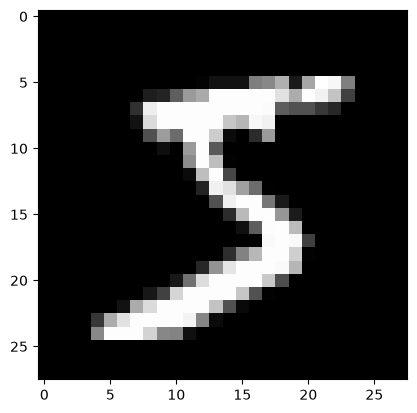

In [47]:
from matplotlib import pyplot
import numpy as np

pyplot.imshow(x_train[0].reshape((28, 28)), cmap="gray")
print(x_train.shape)

torch tensor로 변환

In [48]:
import torch

x_train, y_train, x_valid, y_valid = map(
    torch.tensor, (x_train, y_train, x_valid, y_valid)
)
n, c = x_train.shape
print(x_train, y_train)
print(x_train.shape)
print(y_train.min(), y_train.max())

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]]) tensor([5, 0, 4,  ..., 8, 4, 8])
torch.Size([50000, 784])
tensor(0) tensor(9)


In [49]:
import math

weights = torch.randn(784, 10) / math.sqrt(784)
weights.requires_grad_()
bias = torch.zeros(10, requires_grad=True)

In [50]:
def log_softmax(x):
    return x - x.exp().sum(-1).log().unsqueeze(-1)

def model(xb):
    return log_softmax(xb @ weights + bias)

배치를 나누자!

In [51]:
bs = 64  # 배치 크기

xb = x_train[0:bs]  # x로부터 미니배치(mini-batch) 추출
preds = model(xb)  # 예측 학습전 상황!
preds[0], preds.shape
print(preds[0], preds.shape)

tensor([-1.6062, -2.2473, -2.5756, -2.7936, -2.2170, -2.3374, -2.3017, -2.8266,
        -2.7054, -2.0818], grad_fn=<SelectBackward0>) torch.Size([64, 10])


loss 정의

In [52]:
def nll(input, target):
    return -input[range(target.shape[0]), target].mean()

loss_func = nll

우리의 무작위 모델에 대한 손실을 점검해봅시다, 그럼으로써 우리는 나중에 역전파 이후에 개선이 있는지
확인할 수 있습니다.



In [53]:
yb = y_train[0:bs]
print(loss_func(preds, yb))

tensor(2.3109, grad_fn=<NegBackward0>)


또한, 우리 모델의 정확도(accuracy)를 계산하기 위한 함수를 구현합시다.
매 예측마다, 만약 가장 큰 값의 인덱스가 목표값(target value)과 동일하다면,
그 예측은 올바른 것입니다.



In [54]:
def accuracy(out, yb):
    preds = torch.argmax(out, dim=1)
    return (preds == yb).float().mean()

우리의 무작위 모델의 정확도를 점검해 봅시다, 그럼으로써 손실이 개선됨에 따라서 정확도가 개선되는지
확인할 수 있습니다.



In [55]:
print(accuracy(preds, yb))

tensor(0.0938)


본 학습 시작!

In [56]:
lr = 0.5  # 학습률(learning rate)
epochs = 2  # 훈련에 사용할 에폭(epoch) 수

for epoch in range(epochs):
    for i in range((n - 1) // bs + 1):
        start_i = i * bs
        end_i = start_i + bs
        xb = x_train[start_i:end_i]
        yb = y_train[start_i:end_i]
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        with torch.no_grad():
            weights -= weights.grad * lr
            bias -= bias.grad * lr
            weights.grad.zero_()
            bias.grad.zero_()

결과확인!

In [57]:
print(loss_func(model(xb), yb), accuracy(model(xb), yb))

tensor(0.0797, grad_fn=<NegBackward0>) tensor(1.)


##### **torch.nn.functional**

In [58]:
import torch.nn.functional as F

loss_func = F.cross_entropy

def model(xb):
    return xb @ weights + bias

더이상 ``model`` 함수에서 ``log_softmax`` 를 호출하지 않고 있습니다.
손실과 정확도과 이전과 동일한지 확인해봅시다:



In [59]:
print(loss_func(model(xb), yb), accuracy(model(xb), yb))

tensor(0.0797, grad_fn=<NllLossBackward0>) tensor(1.)


##### **torch.nn.Module**

In [60]:
from torch import nn

class Mnist_Logistic(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(784, 10) / math.sqrt(784))
        self.bias = nn.Parameter(torch.zeros(10))

    def forward(self, xb):
        return xb @ self.weights + self.bias

인스턴스!

In [61]:
model = Mnist_Logistic()

In [62]:
print(loss_func(model(xb), yb))

tensor(2.3382, grad_fn=<NllLossBackward0>)


In [63]:
def fit():
    for epoch in range(epochs):
        for i in range((n - 1) // bs + 1):
            start_i = i * bs
            end_i = start_i + bs
            xb = x_train[start_i:end_i]
            yb = y_train[start_i:end_i]
            pred = model(xb)
            loss = loss_func(pred, yb)

            loss.backward()
            with torch.no_grad():
                for p in model.parameters():
                    p -= p.grad * lr
                model.zero_grad()

fit()

In [64]:
print(loss_func(model(xb), yb))

tensor(0.0803, grad_fn=<NllLossBackward0>)


##### **nn.Linear**




In [65]:
class Mnist_Logistic(nn.Module):
    def __init__(self):
        super().__init__()
        self.lin = nn.Linear(784, 10)

    def forward(self, xb):
        return self.lin(xb)

이전과 같은 방식으로 모델을 인스턴스화하고 손실을 계산합니다:



In [66]:
model = Mnist_Logistic()
print(loss_func(model(xb), yb))

tensor(2.3227, grad_fn=<NllLossBackward0>)


우리는 여전히 이전과 동일한 ``fit`` 메소드를 사용할 수 있습니다.



In [67]:
fit()

print(loss_func(model(xb), yb))

tensor(0.0824, grad_fn=<NllLossBackward0>)


##### ``torch.optim``



In [68]:
from torch import optim

나중에 다시 사용할 수 있도록 모델과 옵티마이져를 만드는 작은 함수를 정의합니다.



In [69]:
def get_model():
    model = Mnist_Logistic()
    return model, optim.SGD(model.parameters(), lr=lr)

model, opt = get_model()
print(loss_func(model(xb), yb))

for epoch in range(epochs):
    for i in range((n - 1) // bs + 1):
        start_i = i * bs
        end_i = start_i + bs
        xb = x_train[start_i:end_i]
        yb = y_train[start_i:end_i]
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))

tensor(2.3026, grad_fn=<NllLossBackward0>)
tensor(0.0810, grad_fn=<NllLossBackward0>)


##### Dataset

In [70]:
from torch.utils.data import TensorDataset

``x_train`` 및 ``y_train`` 모두 하나의 ``TensorDataset`` 에 합쳐질 수 있습니다,
따라서 반복시키고 슬라이스 하기 편리합니다.



In [71]:
train_ds = TensorDataset(x_train, y_train)

In [72]:
model, opt = get_model()

for epoch in range(epochs):
    for i in range((n - 1) // bs + 1):
        xb, yb = train_ds[i * bs: i * bs + bs]
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))

tensor(0.0805, grad_fn=<NllLossBackward0>)


##### ``DataLoader``


In [73]:
from torch.utils.data import DataLoader

train_ds = TensorDataset(x_train, y_train)
train_dl = DataLoader(train_ds, batch_size=bs)

이전에는 루프가 다음과 같이 배치 ``(xb, yb)`` 를 반복했습니다:

::

    for i in range((n-1)//bs + 1):
        xb,yb = train_ds[i*bs : i*bs+bs]
        pred = model(xb)

이제 (xb, yb)가 DataLoader 에서 자동으로 로드되므로 루프가 훨씬 깨끗해졌습니다:

::

    for xb,yb in train_dl:
        pred = model(xb)



In [74]:
model, opt = get_model()

for epoch in range(epochs):
    for xb, yb in train_dl:
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))

tensor(0.0803, grad_fn=<NllLossBackward0>)


PyTorch의 nn.Module, nn.Parameter, Dataset 및 DataLoader 덕분에 이제 훈련 루프가
훨씬 더 작아지고 이해하기 쉬워졌습니다.
이제 실제로 효과적인 모델을 만드는 데 필요한 기본 기능을 추가해 보겠습니다.



##### 검증(validation) 추가하기



In [75]:
train_ds = TensorDataset(x_train, y_train)
train_dl = DataLoader(train_ds, batch_size=bs, shuffle=True)

valid_ds = TensorDataset(x_valid, y_valid)
valid_dl = DataLoader(valid_ds, batch_size=bs * 2)



***Tip!!***

---
- 훈련 전에 항상 ``model.train()`` 을 호출
- 추론(inference) 전에 ``model.eval()``
을 호출합니다, 이는 ``nn.BatchNorm2d`` 및 ``nn.Dropout`` 과 같은 레이어가 동작이 달라짐



In [76]:
model, opt = get_model()

for epoch in range(epochs):
    model.train()
    for xb, yb in train_dl:
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

    model.eval()
    with torch.no_grad():
        valid_loss = sum(loss_func(model(xb), yb) for xb, yb in valid_dl)

    print(epoch, valid_loss / len(valid_dl))

0 tensor(0.2926)
1 tensor(0.3137)


##### fit() 와 get_data() 생성하기

이제 우리는 우리만의 작은 리팩토링을 수행할 것입니다.
훈련 데이터셋과 검증 데이터셋 모두에 대한 손실을 계산하는 유사한 프로세스를 두 번 거치므로,
이를 하나의 배치에 대한 손실을 계산하는 자체 함수 ``loss_batch`` 로 만들어보겠습니다.

훈련 데이터셋에 대한 옵티마이저를 전달하고 이를 사용하여 역전파를 수행합니다.
검증 데이터셋의 경우 옵티마이저를 전달하지 않으므로 메소드가 역전파를 수행하지 않습니다.



In [77]:
def loss_batch(model, loss_func, xb, yb, opt=None):
    loss = loss_func(model(xb), yb)

    if opt is not None:
        loss.backward()
        opt.step()
        opt.zero_grad()

    return loss.item(), len(xb)

``fit`` 은 모델을 훈련하고 각 에폭에 대한 훈련 및 검증 손실을 계산하는 작업을 수행합니다.



In [78]:
import numpy as np

def fit(epochs, model, loss_func, opt, train_dl, valid_dl):
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_dl:
            loss_batch(model, loss_func, xb, yb, opt)

        model.eval()
        with torch.no_grad():
            losses, nums = zip(
                *[loss_batch(model, loss_func, xb, yb) for xb, yb in valid_dl]
            )
        val_loss = np.sum(np.multiply(losses, nums)) / np.sum(nums)

        print(epoch, val_loss)

``get_data`` 는 학습 및 검증 데이터셋에 대한 dataloader 를 출력합니다.



In [79]:
def get_data(train_ds, valid_ds, bs):
    return (
        DataLoader(train_ds, batch_size=bs, shuffle=True),
        DataLoader(valid_ds, batch_size=bs * 2),
    )

이제 dataloader를 가져오고 모델을 훈련하는 전체 프로세스를 3 줄의 코드로 실행할 수 있습니다:



In [80]:
train_dl, valid_dl = get_data(train_ds, valid_ds, bs)
model, opt = get_model()
fit(epochs, model, loss_func, opt, train_dl, valid_dl)

0 0.29834713233709337
1 0.28967576216459273


##### CNN 으로 넘어가기

이제 3개의 컨볼루션 레이어로 신경망을 구축할 것입니다.
이전 섹션의 어떤 함수도 모델의 형식에 대해 가정하지 않기 때문에,
별도의 수정없이 CNN을 학습하는 데 사용할 수 있습니다.

Pytorch의 사전정의된
[Conv2d](https://pytorch.org/docs/stable/nn.html#torch.nn.Conv2d) 클래스를
컨볼루션 레이어로 사용합니다. 3개의 컨볼루션 레이어로 CNN을 정의합니다.
각 컨볼루션 뒤에는 ReLU가 있습니다. 마지막으로 평균 풀링(average pooling)을 수행합니다.
(``view`` 는 PyTorch의 NumPy ``reshape`` 버전입니다.)



In [81]:
class Mnist_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1)
        self.conv2 = nn.Conv2d(16, 16, kernel_size=3, stride=2, padding=1)
        self.conv3 = nn.Conv2d(16, 10, kernel_size=3, stride=2, padding=1)

    def forward(self, xb):
        xb = xb.view(-1, 1, 28, 28)
        xb = F.relu(self.conv1(xb))
        xb = F.relu(self.conv2(xb))
        xb = F.relu(self.conv3(xb))
        xb = F.avg_pool2d(xb, 4)
        return xb.view(-1, xb.size(1))

lr = 0.1

[모멘텀(Momentum)](https://cs231n.github.io/neural-networks-3/#sgd) 은
이전 업데이트도 고려하고 일반적으로 더 빠른 훈련으로 이어지는 확률적 경사하강법(stochastic gradient descent)
의 변형입니다.



In [82]:
model = Mnist_CNN()
opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

fit(epochs, model, loss_func, opt, train_dl, valid_dl)

0 0.40969368901252745
1 0.2568217540025711


##### ``nn.Sequential``



In [83]:
class Lambda(nn.Module):
    def __init__(self, func):
        super().__init__()
        self.func = func

    def forward(self, x):
        return self.func(x)


def preprocess(x):
    return x.view(-1, 1, 28, 28)

``Sequential`` 로 생성된 모들은 간단하게 아래와 같습니다:



In [84]:
model = nn.Sequential(
    Lambda(preprocess),
    nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 16, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 10, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.AvgPool2d(4),
    Lambda(lambda x: x.view(x.size(0), -1)),
)

opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

fit(epochs, model, loss_func, opt, train_dl, valid_dl)

0 0.33357249863147737
1 0.30039042727947235


##### GPU 사용하기

만약 여러분들이 운이 좋아서 CUDA 지원 GPU (대부분의 클라우드 제공 업체에서
시간당 약 $0.50 에 이용할 수 있습니다) 를 사용할 수 있다면, 코드 실행 속도를 높일 수 있습니다.
먼저 GPU가 PyTorch에서 작동하는지 확인합니다:



In [85]:
print(torch.cuda.is_available())

True


그리고 이에 대한 디바이스 오브젝트를 생성합니다:



In [86]:
dev = torch.device(
    "cuda") if torch.cuda.is_available() else torch.device("cpu")

GPU로 배치를 옮기도록 ``preprocess`` 를 업데이트 합시다:



In [93]:
def preprocess(x, y):
    return x.view(-1, 1, 28, 28), y


class WrappedDataLoader:
    def __init__(self, dl, func):
        self.dl = dl
        self.func = func

    def __len__(self):
        return len(self.dl)

    def __iter__(self):
        batches = iter(self.dl)
        for b in batches:
            yield (self.func(*b))
from torch.utils.data import DataLoader

train_ds = TensorDataset(x_train.to(dev), y_train.to(dev))
valid_ds = TensorDataset(x_valid.to(dev), y_valid.to(dev))

train_dl, valid_dl = get_data(train_ds, valid_ds, bs)

train_dl = WrappedDataLoader(train_dl, preprocess)
valid_dl = WrappedDataLoader(valid_dl, preprocess)

마지막으로 모델을 GPU로 이동시킬 수 있습니다.



In [88]:
model.to(dev)
opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

이제 더 빨리 실행됩니다:



In [89]:
fit(epochs, model, loss_func, opt, train_dl, valid_dl)

0 0.22319939453601836
1 0.19184792226552963


## [2교시] Layers

https://pytorch.org/docs/stable/nn.html#convolution-layers

> 자주 들어가서 보자

1. Convolution layer
2. Padding,
3. Pooling
3. Activation이란?

#### Convolution layer


*** What is the convolution ***
![](https://upload.wikimedia.org/wikipedia/commons/thumb/2/21/Comparison_convolution_correlation.svg/2560px-Comparison_convolution_correlation.svg.png)

> 합성곱(合成-), 또는 콘벌루션(convolution)은 하나의 함수와 또 다른 함수를 반전 이동한 값을 곱한 다음, 구간에 대해 적분하여 새로운 함수를 구하는 수학 연산자이다.

= 뒤집고+곱해서+더한다

안뒤집음 cross-correlation

*** What is the convolution layer ***
![](https://lh4.googleusercontent.com/jzUoA82WuYG2SdeQQPhL9oCiAOjMhhfeJ2pPN-tM4d53eWh00uNftD3-YmfOA4TzA-mU1NEHelD8A_JIm2xhib9CqpaRj4DJFZY0AfYO-zMLTHwiY_KTadDl8WOvtSSowjp-hXl0V18rNla5nk-1Dsk)



1.   striding + padding: 몇칸씩 움직일껀가요? 바깥쪽에 덧댈것인가요?


![](https://miro.medium.com/v2/resize:fit:792/0*1CwfqZHE9fGu774w.gif)


3.   dilation: 혹시 퍼트릴껀가요? (띄엄띄엄?)

![](https://cdn-images-1.medium.com/max/497/1*SVkgHoFoiMZkjy54zM_SUw.gif)



**TIP**
Q. 혹시 이상한점 못느끼셨나요?

**torch.nn.conv2d**:
> 어쩌면면 cross-correlation neural network가 맞는 말은 아닐까요?

> 흔히 문제 없다고 말한다. 그러나 FourierCNN과 같이 컨벌루션 연산의 수학적 정의를 따라야하는 경우는 어떨까요?


**torch.nn.fuctional.conv2d**:
> 예외적으로, functional의 conv2d는 실제로 convolution으로 동작합니다.



In [90]:
# https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html#torch.nn.Conv2d
m = nn.Conv2d(16, 33, (3, 5), stride=(2, 1), padding=(4, 2), dilation=(3, 1))
# in_channel, outchannel, kernel_size, stride, ...
input = torch.randn(20, 16, 50, 100)
# batch_size, channel, width, height
# 컨볼루션이 채널을 늘리고(중요) 사이즈를 줄인다.
"""
이 때 채널이 뭘까? RGB?
채널은 표현력이다. 흑백 채널은 채널이 한 개.
흑백이 컬러 사진이 되면 채널이 3개로 늘어난 것.
주어진 토치 텐서 정보를, 채널 단위 정보를 늘려주는 것.

위치 정보를 보존하면서 정보를 늘린다
이걸 풀링 해서 줄여주는 것(2로만 해도 절반)

채널을 늘리고, 풀링으로 줄이고
위치 정보가 채널에 대한 정보로 압축되어 들어가기 시작함
이미지를 넣어서 긴 가래떡을 뽑는 거랑 비슷하게 동작함
"""
output = m(input)

c:\code\.venv\Lib\site-packages\torch\functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4383.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


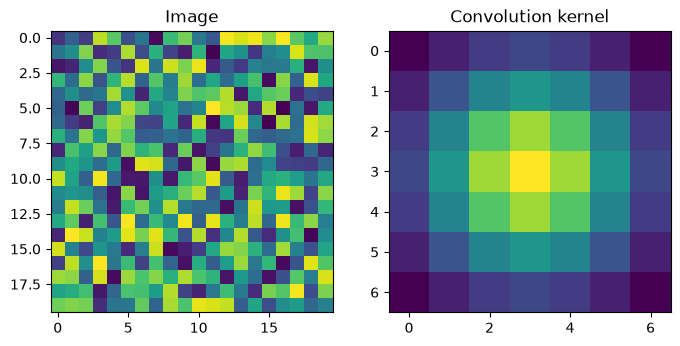

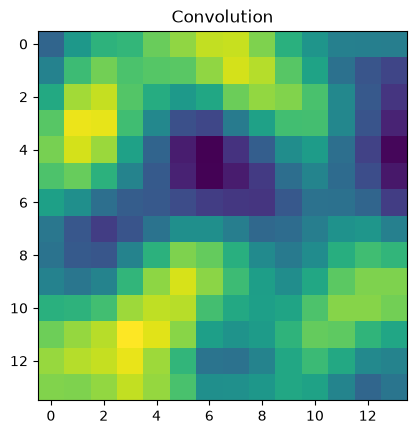

In [91]:
# Creating a images 20x20 made with random value
imgSize = 20
image = torch.rand(imgSize, imgSize)

# typically kernels are created with odd size
kernelSize = 7

# Creating a 2D image
X, Y = torch.meshgrid(torch.linspace(-3,3,kernelSize),torch.linspace(-3,3,kernelSize))

# This is the basic formula for a gaussian, this will make our kernel "pretty"
kernel = torch.exp( -(X**2+Y**2)/7 )

fig,ax = plt.subplots(1,2,figsize=(8,6))
ax[0].imshow(image)
ax[0].set_title('Image')

ax[1].imshow(kernel)
ax[1].set_title('Convolution kernel')

plt.show()
# Pytorch requires the image and the kernel in this format:
# (in_channels, output_channels, imgSizeY, imgSizeX)
image_processed = image.view(1, 1, imgSize, imgSize)
kernel_processed = kernel.view(1,1, kernelSize, kernelSize)

# implementing the convolution
convolution = F.conv2d(image_processed, kernel_processed)

plt.title("Convolution")
# we need to bring back the convolution to a format understandable by Matplotlib
plt.imshow(convolution.view(convolution.shape[2], convolution.shape[3]))

In [92]:
# to read an image from a url
from imageio import imread
# to perform an operation
import numpy as np


lena = 'https://upload.wikimedia.org/wikipedia/ko/thumb/2/24/Lenna.png/220px-Lenna.png'
duck = imread(lena)
print(duck.shape) # should be (612, 530, 3)

# transform image to 2D for convenience (not necessary for convolution!)
# We need numpy because with torch we cannot mean over a specific axis
duck = torch.Tensor(np.mean(duck,axis=2))
duck = duck/torch.max(duck) # scaling the image

# check the size again
print(duck.shape) # should be (612, 530)

# creating the kernels
# vertical kernel
VK = torch.Tensor([ [1,0,-1],
                [1,0,-1],
                [1,0,-1] ]).view(1, 1, 3, 3) # remember? the kernel has to have a specific format

# horizontal kernel
HK = torch.Tensor([ [ 1, 1, 1],
                [ 0, 0, 0],
                [-1,-1,-1] ]).view(1, 1, 3, 3)

fig,ax = plt.subplots(2,2,figsize=(12,10))

# plotting vertical kernel
ax[0,0].imshow(VK.view(3,3))
ax[0,0].set_title('Vertical kernel')

# plotting horizontal kernel
ax[0,1].imshow(HK.view(3,3))
ax[0,1].set_title('Horizontal kernel')

# run convolution and show the result
convolution = F.conv2d(duck.view(1,1,duck.shape[0], duck.shape[1]),VK) # be sure to change the format
ax[1,0].imshow(convolution.view(convolution.shape[2], convolution.shape[3]),cmap='gray',vmin=0,vmax=.01) # we scale the image using vmin and vmax

convolution = F.conv2d(duck.view(1,1,duck.shape[0], duck.shape[1]),HK)
ax[1,1].imshow(convolution.view(convolution.shape[2], convolution.shape[3]),cmap='gray',vmin=0,vmax=.01) # we scale the image using vmin and vmax

plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_11352\74310649.py:8: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  duck = imread(lena)


HTTPError: HTTP Error 403: Forbidden

#### Padding

In [ ]:
# https://pytorch.org/docs/stable/generated/torch.nn.ZeroPad2d.html#torch.nn.ZeroPad2d

m = nn.ZeroPad2d(2)
input = torch.randn(1, 1, 3, 3)
print(input)
print(m(input))
# using different paddings for different sides

m = nn.ZeroPad2d((1, 1, 2, 0))
print(m(input))

In [ ]:
# https://pytorch.org/docs/stable/generated/torch.nn.ReflectionPad1d.html#torch.nn.ReflectionPad1d

m = nn.ReflectionPad1d(2)
input = torch.arange(8, dtype=torch.float).reshape(1, 2, 4)
print(input)
print(m(input))

# using different paddings for different sides
m = nn.ReflectionPad1d((3, 1))
output = m(input)
print(output)

plt.figure()
plt.imshow(input.squeeze().numpy())

plt.figure()
plt.imshow(output.squeeze().numpy())

#### Pooling

1. Max-pooling

![](https://miro.medium.com/v2/resize:fit:1400/1*WvHC5bKyrHa7Wm3ca-pXtg.gif)

2. Min-pooling
3. Max-pooling
4. Average-pooling

In [ ]:
m = nn.AvgPool2d(3, stride=2)
# pool of non-square window
m = nn.AvgPool2d((3, 2), stride=(2, 2))
input = torch.randn(20, 3, 50, 32)
output = m(input)
print(output)


plt.figure()
plt.imshow(input[1,:,:,:].permute(1,2,0).squeeze().numpy())

plt.figure()
plt.imshow(output[1,:,:,:].permute(1,2,0).squeeze().numpy())

#### Activations


![](https://pbs.twimg.com/media/FXo8u7JaQAANoNm.png)

![](https://miro.medium.com/v2/resize:fit:640/1*8VSBCaqL2XeSCZQe_BAyVA.jpeg)


![](https://miro.medium.com/v2/resize:fit:1400/1*m5vrrbH9VvXPoU3jIf7z9w.jpeg)



In [ ]:

# importing the libraries
import torch
import matplotlib.pyplot as plt

# create a PyTorch tensor
x = torch.linspace(-10, 10, 100)

# apply the logistic activation function to the tensor
y = torch.sigmoid(x)

# plot the results with a custom color
plt.plot(x.numpy(), y.numpy(), color='purple')
plt.xlabel('Input')
plt.ylabel('Output')
plt.title('Logistic Activation Function')
plt.show()

In [ ]:
# 활성화 함수 시각화 하는 부분
# apply the tanh activation function to the tensor
#y = torch.tanh(x)
y = torch.relu(x)


# plot the results with a custom color
plt.plot(x.numpy(), y.numpy(), color='blue')
plt.xlabel('Input')
plt.ylabel('Output')
plt.title('Tanh Activation Function')
plt.show()

In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader


# Load the MNIST dataset
transform = transforms.ToTensor()
train_dataset = datasets.MNIST(root='data/', train=True, transform=transform, download=True)
test_dataset = datasets.MNIST(root='data/', train=False, transform=transform, download=True)

train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)


class NeuralNetwork(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes, activation_function):
        super(NeuralNetwork, self).__init__()
        self.layer1 = nn.Linear(input_size, hidden_size)
        self.layer2 = nn.Linear(hidden_size, hidden_size)
        self.layer3 = nn.Linear(hidden_size, num_classes)
        self.activation_function = activation_function

    def forward(self, x):
        x = self.activation_function(self.layer1(x))
        x = self.activation_function(self.layer2(x))
        x = self.layer3(x)
        return x

def train(network, data_loader, criterion, optimizer, device):
    network.train()
    running_loss = 0.0

    for data, target in data_loader:
        data, target = data.to(device), target.to(device)
        data = data.view(data.shape[0], -1)

        optimizer.zero_grad()
        output = network(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * data.size(0)

    return running_loss / len(data_loader.dataset)

def test(network, data_loader, criterion, device):
    network.eval()
    correct = 0
    total = 0
    test_loss = 0.0

    with torch.no_grad():
        for data, target in data_loader:
            data, target = data.to(device), target.to(device)
            data = data.view(data.shape[0], -1)

            output = network(data)
            loss = criterion(output, target)
            test_loss += loss.item() * data.size(0)
            _, predicted = torch.max(output.data, 1)
            total += target.size(0)
            correct += (predicted == target).sum().item()

    return test_loss / len(data_loader.dataset), 100 * correct / total


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
input_size = 784
hidden_size = 128
num_classes = 10
num_epochs = 10
learning_rate = 0.001

activation_functions = {
    'ReLU': nn.ReLU(),
    'Sigmoid': nn.Sigmoid(),
    'Tanh': nn.Tanh(),
    'LeakyReLU': nn.LeakyReLU()
}

results = {}

# Train and test the model with different activation functions
for name, activation_function in activation_functions.items():
    print(f"Training with {name} activation function...")

    model = NeuralNetwork(input_size, hidden_size, num_classes, activation_function).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    train_loss_history = []
    test_loss_history = []
    test_accuracy_history = []

    for epoch in range(num_epochs):
        train_loss = train(model, train_loader, criterion, optimizer, device)
        test_loss, test_accuracy = test(model, test_loader, criterion, device)

        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        test_accuracy_history.append(test_accuracy)

        print(f"Epoch [{epoch+1}/{num_epochs}], Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

    results[name] = {
        'train_loss_history': train_loss_history,
        'test_loss_history': test_loss_history,
        'test_accuracy_history': test_accuracy_history
    }


import matplotlib.pyplot as plt

# Plot the training loss
plt.figure()
for name, data in results.items():
    plt.plot(data['train_loss_history'], label=name)
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.legend()
plt.show()

# Plot the testing loss
plt.figure()
for name, data in results.items():
    plt.plot(data['test_loss_history'], label=name)
plt.xlabel('Epoch')
plt.ylabel('Testing Loss')
plt.legend()
plt.show()

# Plot the testing accuracy
plt.figure()
for name, data in results.items():
    plt.plot(data['test_accuracy_history'], label=name)
plt.xlabel('Epoch')
plt.ylabel('Testing Accuracy')
plt.legend()
plt.show()

### Early stopping

The MNIST training example code is mainly taken from the [mnist_mlp_solution_with_validation.ipynb](https://github.com/udacity/deep-learning-v2-pytorch/blob/master/convolutional-neural-networks/mnist-mlp/mnist_mlp_solution_with_validation.ipynb) notebook from the [deep-learning-v2-pytorch repository](https://github.com/udacity/deep-learning-v2-pytorch) made by [Udacity](https://www.udacity.com/), and has been fitted with my early stopping code.

일찍 마친다?

In [ ]:
from torchvision import datasets
import torchvision.transforms as transforms
from torch.utils.data.sampler import SubsetRandomSampler

def create_datasets(batch_size):

    # percentage of training set to use as validation
    valid_size = 0.2

    # convert data to torch.FloatTensor
    transform = transforms.ToTensor()

    # choose the training and test datasets
    train_data = datasets.MNIST(root='data',
                                train=True,
                                download=True,
                                transform=transform)

    test_data = datasets.MNIST(root='data',
                               train=False,
                               download=True,
                               transform=transform)

    # obtain training indices that will be used for validation
    num_train = len(train_data)
    indices = list(range(num_train))
    np.random.shuffle(indices)
    split = int(np.floor(valid_size * num_train))
    train_idx, valid_idx = indices[split:], indices[:split]

    # define samplers for obtaining training and validation batches
    train_sampler = SubsetRandomSampler(train_idx)
    valid_sampler = SubsetRandomSampler(valid_idx)

    # load training data in batches
    train_loader = torch.utils.data.DataLoader(train_data,
                                               batch_size=batch_size,
                                               sampler=train_sampler,
                                               num_workers=0)

    # load validation data in batches
    valid_loader = torch.utils.data.DataLoader(train_data,
                                               batch_size=batch_size,
                                               sampler=valid_sampler,
                                               num_workers=0)

    # load test data in batches
    test_loader = torch.utils.data.DataLoader(test_data,
                                              batch_size=batch_size,
                                              num_workers=0)

    return train_loader, test_loader, valid_loader

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.5)
    def forward(self, x):
        # flatten image input
        x = x.view(-1, 28 * 28)
        # add hidden layer, with relu activation function
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        # add hidden layer, with relu activation function
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        # add output layer
        x = self.fc3(x)
        return x

# initialize the NN
model = Net()
print(model)

In [ ]:
# specify loss function
criterion = nn.CrossEntropyLoss()

# specify optimizer
optimizer = torch.optim.Adam(model.parameters())

In [ ]:
class EarlyStopping:
    """Early stops the training if validation loss doesn't improve after a given patience."""
    def __init__(self, patience=7, verbose=False, delta=0, path='checkpoint.pt', trace_func=print):
        """
        Args:
            patience (int): How long to wait after last time validation loss improved.
                            Default: 7
            verbose (bool): If True, prints a message for each validation loss improvement.
                            Default: False
            delta (float): Minimum change in the monitored quantity to qualify as an improvement.
                            Default: 0
            path (str): Path for the checkpoint to be saved to.
                            Default: 'checkpoint.pt'
            trace_func (function): trace print function.
                            Default: print
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = np.Inf
        self.delta = delta
        self.path = path
        self.trace_func = trace_func
    def __call__(self, val_loss, model):

        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            self.trace_func(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        '''Saves model when validation loss decrease.'''
        if self.verbose:
            self.trace_func(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}).  Saving model ...')
        torch.save(model.state_dict(), self.path)
        self.val_loss_min = val_loss

Train the Model using Early Stopping

In [ ]:
def train_model(model, batch_size, patience, n_epochs):

    # to track the training loss as the model trains
    train_losses = []
    # to track the validation loss as the model trains
    valid_losses = []
    # to track the average training loss per epoch as the model trains
    avg_train_losses = []
    # to track the average validation loss per epoch as the model trains
    avg_valid_losses = []

    # initialize the early_stopping object
    early_stopping = EarlyStopping(patience=patience, verbose=True)

    for epoch in range(1, n_epochs + 1):

        ###################
        # train the model #
        ###################
        model.train() # prep model for training
        for batch, (data, target) in enumerate(train_loader, 1):
            # clear the gradients of all optimized variables
            optimizer.zero_grad()
            # forward pass: compute predicted outputs by passing inputs to the model
            output = model(data)
            # calculate the loss
            loss = criterion(output, target)
            # backward pass: compute gradient of the loss with respect to model parameters
            loss.backward()
            # perform a single optimization step (parameter update)
            optimizer.step()
            # record training loss
            train_losses.append(loss.item())

        ######################
        # validate the model #
        ######################
        model.eval() # prep model for evaluation
        for data, target in valid_loader:
            # forward pass: compute predicted outputs by passing inputs to the model
            output = model(data)
            # calculate the loss
            loss = criterion(output, target)
            # record validation loss
            valid_losses.append(loss.item())

        # print training/validation statistics
        # calculate average loss over an epoch
        train_loss = np.average(train_losses)
        valid_loss = np.average(valid_losses)
        avg_train_losses.append(train_loss)
        avg_valid_losses.append(valid_loss)

        epoch_len = len(str(n_epochs))

        print_msg = (f'[{epoch:>{epoch_len}}/{n_epochs:>{epoch_len}}] ' +
                     f'train_loss: {train_loss:.5f} ' +
                     f'valid_loss: {valid_loss:.5f}')

        print(print_msg)

        # clear lists to track next epoch
        train_losses = []
        valid_losses = []

        # early_stopping needs the validation loss to check if it has decresed,
        # and if it has, it will make a checkpoint of the current model
        early_stopping(valid_loss, model)

        if early_stopping.early_stop:
            print("Early stopping")
            break

    # load the last checkpoint with the best model
    model.load_state_dict(torch.load('checkpoint.pt'))

    return  model, avg_train_losses, avg_valid_losses

In [ ]:
batch_size = 256
n_epochs = 100

train_loader, test_loader, valid_loader = create_datasets(batch_size)

# early stopping patience; how long to wait after last time validation loss improved.
patience = 20

model, train_loss, valid_loss = train_model(model, batch_size, patience, n_epochs)

***Visualizing the Loss and the Early Stopping Checkpoint***
From the plot we can see that the last Early Stopping Checkpoint was saved right before the model started to overfit.

In [ ]:
# visualize the loss as the network trained
fig = plt.figure(figsize=(10,8))
plt.plot(range(1,len(train_loss)+1),train_loss, label='Training Loss')
plt.plot(range(1,len(valid_loss)+1),valid_loss,label='Validation Loss')

# find position of lowest validation loss
minposs = valid_loss.index(min(valid_loss))+1
plt.axvline(minposs, linestyle='--', color='r',label='Early Stopping Checkpoint')

plt.xlabel('epochs')
plt.ylabel('loss')
plt.ylim(0, 0.5) # consistent scale
plt.xlim(0, len(train_loss)+1) # consistent scale
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
fig.savefig('loss_plot.png', bbox_inches='tight')

Test the Trained Network

In [ ]:
# initialize lists to monitor test loss and accuracy
test_loss = 0.0
class_correct = list(0. for i in range(10))
class_total = list(0. for i in range(10))

model.eval() # prep model for evaluation

for data, target in test_loader:
    if len(target.data) != batch_size:
        break
    # forward pass: compute predicted outputs by passing inputs to the model
    output = model(data)
    # calculate the loss
    loss = criterion(output, target)
    # update test loss
    test_loss += loss.item()*data.size(0)
    # convert output probabilities to predicted class
    _, pred = torch.max(output, 1)
    # compare predictions to true label
    correct = np.squeeze(pred.eq(target.data.view_as(pred)))
    # calculate test accuracy for each object class
    for i in range(batch_size):
        label = target.data[i]
        class_correct[label] += correct[i].item()
        class_total[label] += 1

# calculate and print avg test loss
test_loss = test_loss/len(test_loader.dataset)
print('Test Loss: {:.6f}\n'.format(test_loss))

for i in range(10):
    if class_total[i] > 0:
        print('Test Accuracy of %5s: %2d%% (%2d/%2d)' % (
            str(i), 100 * class_correct[i] / class_total[i],
            np.sum(class_correct[i]), np.sum(class_total[i])))
    else:
        print('Test Accuracy of %5s: N/A (no training examples)' % (classes[i]))

print('\nTest Accuracy (Overall): %2d%% (%2d/%2d)' % (
    100. * np.sum(class_correct) / np.sum(class_total),
    np.sum(class_correct), np.sum(class_total)))

Visualize Sample Test Results

In [ ]:
# obtain one batch of test images
dataiter = iter(test_loader)
images, labels = next(dataiter)

# get sample outputs
output = model(images)
# convert output probabilities to predicted class
_, preds = torch.max(output, 1)
# prep images for display
images = images.numpy()

# plot the images in the batch, along with predicted and true labels
fig = plt.figure(figsize=(25, 4))
for idx in np.arange(20):
    ax = fig.add_subplot(2, 10, idx+1, xticks=[], yticks=[])
    ax.imshow(np.squeeze(images[idx]), cmap='gray')
    ax.set_title("{} ({})".format(str(preds[idx].item()), str(labels[idx].item())),
                 color=("green" if preds[idx]==labels[idx] else "red"))

### ***Dropout***

https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html#torch.nn.Dropout



![](https://miro.medium.com/v2/resize:fit:1184/format:webp/0*vAy-23gZE8UxGwuL.png)


학습시에 과적합을 피하기 위해 확률적으로 몇몇 연결을 생략하고 업데이트 하는 방법

- 드랍아웃은 eval 모드로 들어가면 자동으로 꺼짐(배치 노말라이제이션도 마찬가지)



In [ ]:
m = nn.Dropout(p=0.8)
input = torch.randn(20, 16)
output = m(input)

plt.figure()
plt.imshow(input)
plt.figure()
plt.imshow(output)

In [ ]:

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

transform = transforms.Compose([
  transforms.ToTensor(),
  transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 64

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

train_dataset = torchvision.datasets.CIFAR10(root="./data", train=True,
                                             download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size,
                                           shuffle=True, num_workers=2)

test_dataset = torchvision.datasets.CIFAR10(root="./data", train=False,
                                             download=True, transform=transform)

test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size,
                                           shuffle=False, num_workers=2)

# the MNIST classes
classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

In [ ]:

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

net = Net()
net.to(device)

In [ ]:
import torch.optim as optim
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

def get_test_loss(net, criterion, data_loader):
  """It iterates over `data_loader` to calculate the overall loss"""
  testing_loss = []
  with torch.no_grad():
    for data in data_loader:
      inputs, labels = data
      inputs, labels = inputs.to(device), labels.to(device)
      outputs = net(inputs)
      # calculate the loss for this batch
      loss = criterion(outputs, labels)
      # add the loss of this batch to the list
      testing_loss.append(loss.item())
  # calculate the average loss
  return sum(testing_loss) / len(testing_loss)


In [ ]:
training_loss, testing_loss = [], []
running_loss = []
i = 0
for epoch in range(150): # 150 epochs
  for data in train_loader:
    inputs, labels = data
    # get the data to GPU (if available)
    inputs, labels = inputs.to(device), labels.to(device)
    optimizer.zero_grad()
    # forward pass
    outputs = net(inputs)
    # backward pass
    loss = criterion(outputs, labels)
    loss.backward()
    # update gradients
    optimizer.step()
    running_loss.append(loss.item())
    i += 1
    if i % 1000 == 0:
      avg_train_loss = sum(running_loss) / len(running_loss)
      avg_test_loss = get_test_loss(net, criterion, test_loader)
      # clear the list
      running_loss.clear()
      training_loss.append(avg_train_loss)
      testing_loss.append(avg_test_loss)
      print(f"[{epoch:2d}] [it={i:5d}] Train Loss: {avg_train_loss:.3f}, Test Loss: {avg_test_loss:.3f}")


In [ ]:
class NetDropout(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.do1 = nn.Dropout(0.2)  # 20% Probability
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.do2 = nn.Dropout(0.2)  # 20% Probability
        self.fc2 = nn.Linear(120, 84)
        self.do3 = nn.Dropout(0.1)  # 10% Probability
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.do1(x)
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = self.do2(x)
        x = F.relu(self.fc2(x))
        x = self.do3(x)
        x = self.fc3(x)
        return x


net_dropout = NetDropout()
net_dropout.to(device)

In [ ]:

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net_dropout.parameters(), lr=0.001, momentum=0.9)


training_loss_d, testing_loss_d = [], []
running_loss = []
i = 0
for epoch in range(150): # 10 epochs
  for data in train_loader:
    inputs, labels = data
    # get the data to GPU (if available)
    inputs, labels = inputs.to(device), labels.to(device)

    optimizer.zero_grad()
    # forward pass
    outputs = net_dropout(inputs)
    # backward pass
    loss = criterion(outputs, labels)
    loss.backward()
    # update gradients
    optimizer.step()
    running_loss.append(loss.item())
    i += 1
    if i % 1000 == 0:
      avg_train_loss = sum(running_loss) / len(running_loss)
      avg_test_loss = get_test_loss(net_dropout, criterion, test_loader)
      # clear the list
      running_loss.clear()
      # for logging & plotting later
      training_loss_d.append(avg_train_loss)
      testing_loss_d.append(avg_test_loss)
      print(f"[{epoch:2d}] [it={i:5d}] Train Loss: {avg_train_loss:.3f}, Test Loss: {avg_test_loss:.3f}")

In [ ]:
plt.plot(testing_loss, label="without dropout")
plt.plot(testing_loss_d, label="with dropout")
plt.legend()
plt.title("The Cross-entropy loss of the MNIST test data with and w/o Dropout")
plt.show()

### ***Gradient vanishing***


![](https://blog.kakaocdn.net/dn/okTU1/btrCH4Fx7Ro/m5f9UkRkl7CP3dUEgXTtk1/img.png)

시기: "시각 인공지능 계층이 깊어지기 시작한 때"
현상: 역전파 과정에서 앞으로 오면 올수록 값이 점점 작아지는 문제 발견
원인: 기존에 sigmoid 때문이었다!
![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FyJnMy%2FbtrCKh4ojvw%2FLtlaMwrtEZHC3KtGNWvuLK%2Fimg.png)

**tanh 등장!**
![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fcq4ZGq%2FbtrCJJNA2bI%2FZhOpBc6Rj3061ZMw11AfPK%2Fimg.png)

스케일만 좀 커졌다뿐이지 똑같은 문제 발생

근본적인 해결책 필요..

***relu 등장!***
![](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fcf41pg%2FbtrCKjuuLjU%2FqtdsmkQ2xB7xf5MuKYtaUK%2Fimg.png)


드디어 폭발적인 적층의 시대 도래!!!

---

Tip: LeakyReLU도 좋습니다!

> What is the dying relu problem?
> see: https://towardsdatascience.com/the-dying-relu-problem-clearly-explained-42d0c54e0d24

> 해결책: ELU, LeakyReLU 참조해 보세요 (https://pytorch.org/docs/stable/generated/torch.nn.ELU.html#torch.nn.ELU)

### Grdient clipping

https://pytorch.org/docs/stable/generated/torch.nn.utils.clip_grad_norm_.html


![](https://blog.kakaocdn.net/dn/PRtdv/btrijTKa3AA/lO27DGHxRyNDzUd7TusXtk/img.png)

![](https://blog.kakaocdn.net/dn/co004I/btrbtx882Im/w9I77xg7zp4gHSwtTchnKK/img.png)

![](https://blog.kakaocdn.net/dn/bhDouC/btqJnEUH6N4/cHCdmBGndw51Wu8LV9dFt1/img.png)

In [ ]:
import torch.nn as nn
import torch.optim as optim

# Define a simple neural network
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(10, 5)
        self.fc2 = nn.Linear(5, 1)

    def forward(self, x):
        x = nn.functional.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Create an instance of the neural network
net = Net()

# Define the optimizer and loss function
optimizer = optim.SGD(net.parameters(), lr=0.01)
criterion = nn.MSELoss()

# inputs, labels = data
inputs = torch.randn(1,1,10)
lables = torch.ones(1,1,1)


# Zero the parameter gradients
optimizer.zero_grad()

# Forward + backward + optimize
outputs = net(inputs)
loss = criterion(outputs, labels)
loss.backward()
nn.utils.clip_grad_norm_(net.parameters(), 1.0)
optimizer.step()

## [3교시] MNIST + CNN

1. convolution?: convolution, stride, padding

2. pooling?

3. Activation!



In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (8, 8)

 Convolution operator
- Problems with the Fully-connected nn
    - Do you need to consider all the relations between the features?
    - Fully connected nn are big and so very computationally inefficient
    - They have so many parameters, and so overfit
- Main idea of CNN
    - Units are connected with only a few units from the previous layer
    - Units share weights

![](https://miro.medium.com/v2/resize:fit:1358/1*vkQ0hXDaQv57sALXAJquxA.jpeg)


- Convolving operation
![convolution2](https://uploads-ssl.webflow.com/614c82ed388d53640613982e/646371e3bdc5ca90dee5331b_convolutional-neural-network%20(1).webp)


- Activation map
![act](image/act_map.png)

RGB 각각에 대한 커널이 하나씩 있고, 이게 아웃풋 채널 개수만큼 쌍이 있는 것. 8채널 아웃풋이면 3x8

### Convolution operator - OOP way
Let's kick off this chapter by using convolution operator from the `torch.nn` package. You are going to create a random tensor which will represent your image and random filters to convolve the image with. Then you'll apply those images.

In [ ]:
# Create 10 random images of shape (1, 28, 28)
images = torch.rand(10, 1, 28, 28)

# Build 6 conv. filters
conv_filters = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=(3, 3), stride=1, padding=1)

# Convolve the image with the filters
output_feature = conv_filters(images)
print(output_feature.shape)

### Convolution operator - Functional way
While I and most of PyTorch practitioners love the `torch.nn` package (OOP way), other practitioners prefer building neural network models in a more functional way, using `torch.nn.functional`. More importantly, it is possible to mix the concepts and use both libraries at the same time (we have already done it in the previous chapter). You are going to build the same neural network you built in the previous exercise, but this time using the functional way.

In [ ]:
# Create 10 random images
images = torch.rand(10, 1, 28, 28)

# Create 6 filters
filters = torch.rand(6, 1, 3, 3)

# Convolve the image with the filters
output_feature = F.conv2d(images, filters, stride=1, padding=1)
print(output_feature.shape)

### Pooling operators
- 입력은 이미지.. convoluiond에 의해 늘어난 채널 정보..
- 채널로 늘어난 정보.. 최종 결정을 위해선 크기를 줄여야 되지 않을까요?


![](https://velog.velcdn.com/images%2Fntk1750%2Fpost%2F923105d8-1649-4bc5-8516-b634cc6284e6%2F20220118_184914_2.png)

- Max-Pooling: 영역내 최고를 찾음

- Average-Pooling: 영역 내 평균을 찾음

![](https://cdn-images-1.medium.com/max/726/1*fXxDBsJ96FKEtMOa9vNgjA.gif)

### Max-pooling operator
Here you are going to practice using max-pooling in both OOP and functional way, and see for yourself that the produced results are the same.

In [ ]:
im = torch.rand(1, 1, 6, 6)
im

In [ ]:
# Build a pooling operator with size 2
max_pooling = nn.MaxPool2d(2)

# Apply the pooling operator
output_feature = max_pooling(im)

# Use pooling operator in the image
output_feature_F = F.max_pool2d(im, 2)

# Print the results of both cases
print(output_feature)
print(output_feature_F)

### Average-pooling operator
After coding the max-pooling operator, you are now going to code the average-pooling operator. You just need to replace max-pooling with average pooling.



In [ ]:
# Build a pooling operator with size 2
avg_pooling = nn.AvgPool2d(2)

# Apply the pooling operator
output_feature = avg_pooling(im)

# Use pooling operator in the image
output_feature_F = F.avg_pool2d(im, 2)

# Print the results of both cases
print(output_feature)
print(output_feature_F)

### 역사적인 모델 살펴보기: AlexNet
![alexnet](https://raw.githubusercontent.com/Masterx-AI/AlexNet-Implementation/main/AlexNet.png)

> AlexNet은 2012년에 개최된 ILSVRC(ImageNet Large Scale Visual Recognition Challenge) 대회의 우승을 차지한 컨볼루션 신경망(CNN) 구조이다. CNN의 부흥에 아주 큰 역할을 한 구조



```python
class AlexNet(nn.Module):
    def __init__(self, num_classes=1000):
        super(AlexNet, self).__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=11, stride=4, padding=2)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2)
        self.conv2 = nn.Conv2d(64, 192, kernel_size=5, padding=2)
        self.conv3 = nn.Conv2d(192, 384, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(384, 256, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        self.avgpool = nn.AdaptiveAvgPool2d((6, 6))
        self.fc1 = nn.Linear(256 * 6 * 6, 4096)
        self.fc2 = nn.Linear(4096, 4096)
        self.fc3 = nn.Linear(4096, num_classes)
        
    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.maxpool(x)
        x = self.relu(self.conv2(x))
        x = self.maxpool(x)
        x = self.relu(self.conv3(x))
        x = self.relu(self.conv4(x))
        x = self.relu(self.conv5(x))
        x = self.maxpool(x)
        x = self.avgpool(x)
        x = x.view(x.size(0), 256 * 6 * 6)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.fc3(x)
```

만들어보자!!

In [ ]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()

        # Instantiate two convolutional layers
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=5, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_channels=5, out_channels=10, kernel_size=3, padding=1)

        # Instantiate the ReLU nonlinearity
        self.relu = nn.ReLU(inplace=True)

        # Instantiate a max pooling layer
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Instantiate a fully connected layer
        self.fc = nn.Linear(49 * 10, 10)

    def forward(self, x):
        # Apply conv followed by relu, then in next line pool
        x = self.relu(self.conv1(x))
        x = self.pool(x)

        # Apply conv followed by relu, then in next line pool
        x = self.relu(self.conv2(x))
        x = self.pool(x)

        # Prepare the image for the fully connected layer
        x = x.view(-1, 7 * 7 * 10)

        # Apply the fully connected layer and return the result
        return self.fc(x)

In [ ]:
import torchvision.transforms as transforms

# Transform the data to torch tensors and normalize it
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307), (0.3081))
])

# Preparing the training and test set
trainset = torchvision.datasets.MNIST('mnist', train=True, transform=transform, download=True)
testset = torchvision.datasets.MNIST('mnist', train=False, transform=transform, download=True)

# Prepare loader
train_loader = torch.utils.data.DataLoader(trainset, batch_size=1, shuffle=True, num_workers=0)
test_loader = torch.utils.data.DataLoader(testset, batch_size=1, shuffle=False, num_workers=0)

In [ ]:
import torch.optim as optim

net = Net()
optimizer = optim.Adam(net.parameters(), lr=3e-4)
criterion = nn.CrossEntropyLoss()

In [ ]:
for i, data in enumerate(train_loader, 0):
    inputs, labels = data
    optimizer.zero_grad()

    # Compute the forward pass
    outputs = net(inputs)

    # Compute the loss function
    loss = criterion(outputs, labels)

    # Compute the gradients
    loss.backward()

    # Update the weights
    optimizer.step()

In [ ]:
net.eval()
# Iterate over the data in the test_loader
for i, data in enumerate(test_loader):
    # Get the image and label from data
    image, label = data

    # Make a forward pass in the net with your image
    output = net(image)

    # Argmax the results of the net
    _, predicted = torch.max(output.data, 1)

    if predicted == label:
        print("Yipes, your net made the right prediction " + str(predicted))
    else:
        print("Your net prediction was " + str(predicted) + ", but the correct label is: " + str(label))

    if i > 10:
        break

## [4교시] Siamese Network

두 장의 사진을 비교하는건 어떨까?
1. 임베딩
2. 비교
3. 학습?



설명그림1.

![](https://miro.medium.com/v2/resize:fit:1400/1*0E9104t29iMBmtvq7G1G6Q.png)



설명그림2.

![](https://kr.mathworks.com/help/examples/nnet/win64/TrainASiameseNetworkForDimensionalityReductionExample_03.png)


---


Contrastive loss
- 같으면 Y==1: D가 줄어들어야 된다.
- 다르면 Y==0: max(m-D,0)가 줄어들어야 된다.
> D가 늘어나야 된다. (단, m보다 커지면 똑같은 효과)


![](https://b2633864.smushcdn.com/2633864/wp-content/uploads/2021/01/contrastive_loss_keras_header_updated.png?lossy=2&strip=1&webp=1)


Q. 절대 거리에 대한 기준이 애매하다. 마진의 길이는 어떻게 할건지?

---


triplet loss

- positive pair: dp
- negative pair: dn
- loss = max(0,dp-dn+a)

> 상대 거리 자체를 학습하는 것.
> 여기서 마진은 두 거리차를 더 벌리기 위한 것. (dp+a - dn)>0 을 만족시키기 위함

![](https://miro.medium.com/v2/resize:fit:1400/1*MIPdyhJGx6uLiob9UI9S0w.png)


In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import random
from PIL import Image
import PIL.ImageOps

import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
import torchvision.utils
import torch
from torch.autograd import Variable
import torch.nn as nn
from torch import optim
import torch.nn.functional as F

In [ ]:
# Creating some helper functions
def imshow(img, text=None):
    npimg = img.numpy()
    plt.axis("off")
    if text:
        plt.text(75, 8, text, style='italic',fontweight='bold',
            bbox={'facecolor':'white', 'alpha':0.8, 'pad':10})

    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

def show_plot(iteration,loss):
    plt.plot(iteration,loss)
    plt.show()

In [ ]:
class SiameseNetworkDataset(Dataset):
    def __init__(self,imageFolderDataset,transform=None):
        self.imageFolderDataset = imageFolderDataset
        self.transform = transform

    def __getitem__(self,index):
        img0_tuple = random.choice(self.imageFolderDataset.imgs)

        #We need to approximately 50% of images to be in the same class
        should_get_same_class = random.randint(0,1)
        if should_get_same_class:
            while True:
                #Look untill the same class image is found
                img1_tuple = random.choice(self.imageFolderDataset.imgs)
                if img0_tuple[1] == img1_tuple[1]:
                    break
        else:

            while True:
                #Look untill a different class image is found
                img1_tuple = random.choice(self.imageFolderDataset.imgs)
                if img0_tuple[1] != img1_tuple[1]:
                    break

        img0 = Image.open(img0_tuple[0])
        img1 = Image.open(img1_tuple[0])

        img0 = img0.convert("L")
        img1 = img1.convert("L")

        if self.transform is not None:
            img0 = self.transform(img0)
            img1 = self.transform(img1)

        return img0, img1, torch.from_numpy(np.array([int(img1_tuple[1] != img0_tuple[1])], dtype=np.float32))

    def __len__(self):
        return len(self.imageFolderDataset.imgs)

#### 데이터 다운로드
https://www.kaggle.com/datasets/kasikrit/att-database-of-faces?resource=download
> 우상단 download 누르면 됨

> 혹은 아래 github에서 받아도 됨. thanks to 착한 사람.


In [ ]:
!wget https://github.com/maticvl/dataHacker/raw/master/DATA/at%26t.zip
!rm -rf data
!unzip "at&t.zip" -d .

In [ ]:
# Load the training dataset
folder_dataset = datasets.ImageFolder(root="./data/faces/training/")

In [ ]:
# Resize the images and transform to tensors
transformation = transforms.Compose([transforms.Resize((100,100)),
                                     transforms.ToTensor()
                                    ])

# Initialize the network
siamese_dataset = SiameseNetworkDataset(imageFolderDataset=folder_dataset,
                                        transform=transformation)

In [ ]:
# Create a simple dataloader just for simple visualization
vis_dataloader = DataLoader(siamese_dataset,
                        shuffle=True,
                        num_workers=2,
                        batch_size=8)

# Extract one batch
example_batch = next(iter(vis_dataloader))

# Example batch is a list containing 2x8 images, indexes 0 and 1, an also the label
# If the label is 1, it means that it is not the same person, label is 0, same person in both images
concatenated = torch.cat((example_batch[0], example_batch[1]),0)

imshow(torchvision.utils.make_grid(concatenated))
print(example_batch[2].numpy().reshape(-1))

In [ ]:
#create the Siamese Neural Network
class SiameseNetwork(nn.Module):

    def __init__(self):
        super(SiameseNetwork, self).__init__()

        # Setting up the Sequential of CNN Layers
        self.cnn1 = nn.Sequential(
            nn.Conv2d(1, 96, kernel_size=11,stride=4),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2),

            nn.Conv2d(96, 256, kernel_size=5, stride=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, stride=2),

            nn.Conv2d(256, 384, kernel_size=3,stride=1),
            nn.ReLU(inplace=True)
        )

        # Setting up the Fully Connected Layers
        self.fc1 = nn.Sequential(
            nn.Linear(384, 1024),
            nn.ReLU(inplace=True),

            nn.Linear(1024, 256),
            nn.ReLU(inplace=True),

            nn.Linear(256,2)
        )

    def forward_once(self, x):
        # This function will be called for both images
        # It's output is used to determine the similiarity
        output = self.cnn1(x)
        output = output.view(output.size()[0], -1)
        output = self.fc1(output)
        return output

    def forward(self, input1, input2):
        # In this function we pass in both images and obtain both vectors
        # which are returned
        output1 = self.forward_once(input1)
        output2 = self.forward_once(input2)

        return output1, output2

In [ ]:
# Define the Contrastive Loss Function
class ContrastiveLoss(torch.nn.Module):
    def __init__(self, margin=2.0):
        super(ContrastiveLoss, self).__init__()
        self.margin = margin

    def forward(self, output1, output2, label):
      # Calculate the euclidian distance and calculate the contrastive loss
      euclidean_distance = F.pairwise_distance(output1, output2, keepdim = True)

      loss_contrastive = torch.mean((1-label) * torch.pow(euclidean_distance, 2) +
                                    (label) * torch.pow(torch.clamp(self.margin - euclidean_distance, min=0.0), 2))


      return loss_contrastive

In [ ]:
# Load the training dataset
train_dataloader = DataLoader(siamese_dataset,
                        shuffle=True,
                        num_workers=8,
                        batch_size=64)

In [ ]:
net = SiameseNetwork().cuda()
criterion = ContrastiveLoss()
optimizer = optim.Adam(net.parameters(), lr = 0.0005 )

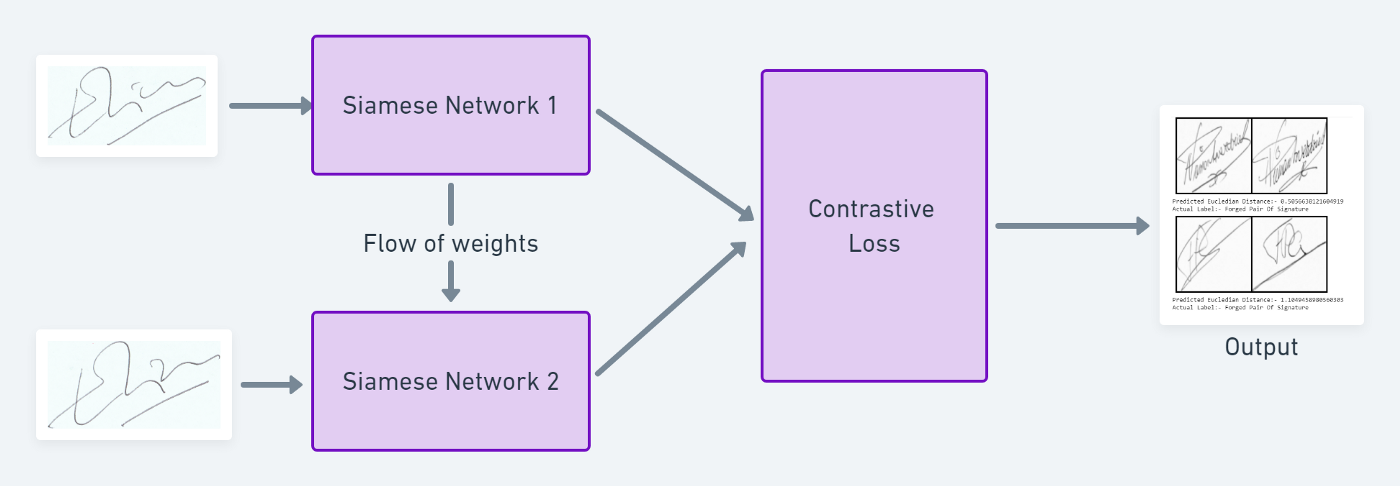

In [ ]:
counter = []
loss_history = []
iteration_number= 0

# Iterate throught the epochs
for epoch in range(100):

    # Iterate over batches
    for i, (img0, img1, label) in enumerate(train_dataloader, 0):

        # Send the images and labels to CUDA
        img0, img1, label = img0.cuda(), img1.cuda(), label.cuda()

        # Zero the gradients
        optimizer.zero_grad()

        # Pass in the two images into the network and obtain two outputs
        output1, output2 = net(img0, img1)

        # Pass the outputs of the networks and label into the loss function
        loss_contrastive = criterion(output1, output2, label)

        # Calculate the backpropagation
        loss_contrastive.backward()

        # Optimize
        optimizer.step()

        # Every 10 batches print out the loss
        if i % 10 == 0 :
            print(f"Epoch number {epoch}\n Current loss {loss_contrastive.item()}\n")
            iteration_number += 10

            counter.append(iteration_number)
            loss_history.append(loss_contrastive.item())

show_plot(counter, loss_history)

In [ ]:
# Locate the test dataset and load it into the SiameseNetworkDataset
folder_dataset_test = datasets.ImageFolder(root="./data/faces/testing/")
siamese_dataset = SiameseNetworkDataset(imageFolderDataset=folder_dataset_test,
                                        transform=transformation)
test_dataloader = DataLoader(siamese_dataset, num_workers=2, batch_size=1, shuffle=True)

# Grab one image that we are going to test
dataiter = iter(test_dataloader)
x0, _, _ = next(dataiter)

for i in range(10):
    # Iterate over 10 images and test them with the first image (x0)
    _, x1, label2 = next(dataiter)

    # Concatenate the two images together
    concatenated = torch.cat((x0, x1), 0)

    output1, output2 = net(x0.cuda(), x1.cuda())
    euclidean_distance = F.pairwise_distance(output1, output2)
    imshow(torchvision.utils.make_grid(concatenated), f'Dissimilarity: {euclidean_distance.item():.2f}')

#### 다른예제: omniglot

출처: https://colab.research.google.com/drive/1TDjk36ia5rTXQPHpAgfwZvPDmXbHetui?usp=sharing#scrollTo=hmpaCmVHGct2



In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms, utils, datasets
import torch.optim as optim

import numpy as np
from PIL import Image
import os
from tqdm import tqdm
import random
import matplotlib.pyplot as plt

In [ ]:
print(torch.__version__)

In [ ]:
# Model
class Siamese_Net(nn.Module):
  def __init__(self):
    super(Siamese_Net,self).__init__()

    self.conv1=nn.Conv2d(1,64,10)
    self.conv2=nn.Conv2d(64,128,7)
    self.conv3=nn.Conv2d(128,128,4)
    self.conv4=nn.Conv2d(128,256,4)

    self.Linear1=nn.Linear(9216,4096)
    self.flatten=nn.Flatten()
    self.Linear2=nn.Linear(4096,1)

    self.relu=nn.ReLU()
    self.maxP=nn.MaxPool2d(2)
    self.sigm=nn.Sigmoid()

    # self.initialize_weights()

  def twin(self,x):

    out=self.conv1(x)
    out=self.relu(out)
    out=self.maxP(out)

    out=self.conv2(out)
    out=self.relu(out)
    out=self.maxP(out)

    out=self.conv3(out)
    out=self.relu(out)
    out=self.maxP(out)

    out=self.conv4(out)
    out=self.relu(out)

    # test=out.view(out.size()[0], -1)
    out=self.flatten(out)
    # print(test==out) ##result -> true

    out=self.Linear1(out)
    out=self.sigm(out)

    return out

  def forward(self,x1,x2):

    x1_out=self.twin(x1)
    x2_out=self.twin(x2)

    # score= linear(distance between vectors)
    score=self.Linear2(torch.abs(x1_out-x2_out))

    # print(score)

    return score

  def initialize_weights(self):
    for m in self.modules():
      if isinstance(m,nn.Conv2d):
        nn.init.normal_(m.weight,0,1e-2)
        nn.init.normal_(m.bias, 0.5, 1e-2)
      if isinstance(m,nn.Linear):
        nn.init.normal_(m.weight,0,2e-2)
        nn.init.normal_(m.bias, 0.5, 1e-2)



In [ ]:
#testing
net=Siamese_Net()
# print(net)
dummyx1=torch.randn(64,1,105,105)
dummyx2=torch.randn(64,1,105,105)
o=net(dummyx1,dummyx2)
print(o.shape)

##### **Omniglot Dataset**

In [ ]:
# download the dataset
omni_train=datasets.Omniglot(root='/content',
                       background= True,
                       download = True
                       )

omni_test=datasets.Omniglot(root='/content',
                       background= False,
                       download = True
                       )

In [ ]:
# Omniglot dataset- didnt rename cause would have had to rename it everywhere
class Face_Dataset(Dataset):
  def __init__(self,root_dir, job='train',ways=10,transform=None):
    super(Face_Dataset,self).__init__()
    self.root_dir=root_dir
    self.job=job
    self.all_classes=os.listdir(root_dir)
    self.num_classes=len(self.all_classes)
    self.face_list, self.number_of_faces=self.get_char_list()
    self.ways=ways
    self.transform=transform
    print(self.all_classes)

  def __len__(self):
    return self.number_of_faces

  def __getitem__(self,idx):
    if self.job=='train':
      is_Same=1
      # Same person if even
      if idx%2==0:
        path_img_1,path_img_2,_=self.get_same()
      # different people
      else:
        is_Same=0
        path_img_1,path_img_2=self.get_different()

      img1=Image.open(path_img_1).convert('L')
      img2=Image.open(path_img_2).convert('L')

      if self.transform:
        img1=self.transform(img1)
        img2=self.transform(img2)

      return img1,img2,torch.tensor([is_Same], dtype=torch.float32)

    else:
      img_list=[]
      ways=self.ways

      # grab two images from the same class
      path_img_1,path_img_2,id_to_avoid=self.get_same()
      img_list+=[path_img_1,path_img_2]

      ways=(ways-2)//2

      # and remaining from different classes
      for i in range(ways):
        img_list+=self.get_different(id_to_avoid)

      for i in range(len(img_list)):
        img=Image.open(img_list[i]).convert('L')
        if self.transform:
          img=self.transform(img)
        img_list[i]=img

      img_list_tensor=torch.stack(img_list)
      return img_list_tensor

  def get_char_list(self) -> (dict, int):
      a_list,n_letters={},0
      for idx, alpha in enumerate(self.all_classes):
        a_list[idx]=[]
        for char in os.listdir(os.path.join(self.root_dir,alpha)):
          l_list=[]
          for letter in os.listdir(os.path.join(self.root_dir,alpha,char)):
            l_list.append(os.path.join(self.root_dir,alpha,char,letter))
            n_letters+=1
          a_list[idx].append(l_list)
      return a_list,n_letters

  def get_same(self) -> (str, str, int):
    alpha_id=random.randint(0,self.num_classes-1)
    char_id=random.randint(0,len(self.face_list[alpha_id])-1)
    path_img_1=random.choice(self.face_list[alpha_id][char_id])
    path_img_2=random.choice(self.face_list[alpha_id][char_id])
    return path_img_1,path_img_2,char_id

  def get_different(self, avoid=None)-> (str, str):

    alpha_id_1=random.randint(0,self.num_classes-1)
    char_id_1=random.randint(0,len(self.face_list[alpha_id_1])-1)
    while char_id_1==avoid:
      char_id_1=random.randint(0,len(self.face_list[alpha_id_1])-1)

    alpha_id_2=random.randint(0,self.num_classes-1)
    char_id_2=random.randint(0,len(self.face_list[alpha_id_2])-1)
    while char_id_2==char_id_1 or char_id_2==avoid:
      char_id_2=random.randint(0,len(self.face_list[alpha_id_2])-1)

    path_img_1=random.choice(self.face_list[alpha_id_1][char_id_1])
    path_img_2=random.choice(self.face_list[alpha_id_2][char_id_2])
    return path_img_1,path_img_2


In [ ]:
a=torch.randn((64,3,122,450),dtype=torch.float32)
b=torch.randn((64,3,122,450),dtype=torch.float32)
c=torch.randn((64,3,122,450),dtype=torch.float32)
l=[a,b,c]
lt=torch.stack(l)
print(lt.shape)
print(lt[0,:].shape)

In [ ]:
# omniglot root
train_root='/content/omniglot-py/images_background'
val_root='/content/omniglot-py/images_evaluation'
batch_size=16
ways=10

In [ ]:
# Omniglot Calculating the mean and std of the data

def find_mean_std(datasets,batch_s=1):

  means_stds=[]
  for dataset in datasets:
    to_norm_loader=DataLoader(dataset=dataset, batch_size=batch_s)
    print('Total number of samples: ', len(dataset))

    # #run for 1 batch
    # data_iter=iter(to_norm_loader)
    # img,_,__=data_iter.next()
    # print(img.shape)

    channels_sum, channels_squared_sum, num_batches=0, 0, 0
    for img,_,__ in to_norm_loader:
      # print(img.shape)#[batch,C,H,W]
      channels_sum+=torch.mean(img,dim=[0,2,3])
      channels_squared_sum+=torch.mean(img**2,dim=[0,2,3])
      num_batches+=1

    mean=channels_sum/num_batches
    std=(channels_squared_sum/num_batches- mean**2)**0.5
    means_stds.append(mean)
    means_stds.append(std)
  return means_stds

to_be_norm_dataset=Face_Dataset(train_root, transform=transforms.Compose([
                                                             transforms.Resize((105,105)),
                                                             transforms.ToTensor()
                                           ]))

to_be_norm_dataset_val=Face_Dataset(val_root, transform=transforms.Compose([
                                                             transforms.Resize((105,105)),
                                                             transforms.ToTensor()
                                           ]))

mean, std,mean_val,std_val= find_mean_std([to_be_norm_dataset, to_be_norm_dataset_val], batch_s=batch_size)

print(f'mean: {mean.item()}    std: {std.item()}     val mean: {mean_val.item()}    val std: {std_val.item()}')

In [ ]:
# prepare datasets(OMNIGLOT)

transform=transforms.Compose([
                              transforms.Resize((105,105)),
                              transforms.RandomAffine(30,shear=0.2),
                              transforms.ToTensor(),
                              transforms.Normalize([mean.item()],[std.item()]),
])
# dataset=Face_Dataset(root,transform=transform)
dataset_train=Face_Dataset(train_root, transform=transform)
dataset_val=Face_Dataset(val_root,job='val', ways=ways, transform=transforms.Compose([transforms.Resize((105,105)),
                                                            transforms.ToTensor(),
                                                            transforms.Normalize([mean_val.item()],[std_val.item()])
                                                            ])
)

dataloader_train=DataLoader(dataset=dataset_train, batch_size=batch_size)
dataloader_val=DataLoader(dataset=dataset_val, batch_size=batch_size)


##### Check if the datasets are working

In [ ]:
# Testing train Dataset
img1,img2,are_Same=dataset_train[1]

print(are_Same.item())
print(img1.shape,'\n',img2.shape)

# convert to PIL and multiply with std and add mean to un-normalize the images for viewing purposes only
show_img1=transforms.ToPILImage()(img1.mul_(std).add_(mean))
show_img2=transforms.ToPILImage()(img2.mul_(std).add_(mean))

print(show_img1.size,'\n',show_img2.size)

plt.subplot(121)
plt.imshow(show_img1,cmap='gray')

plt.subplot(122)
plt.imshow(show_img2,cmap='gray')


In [ ]:
# Testing validation Dataset
imgs=dataset_val[0]

print(imgs.shape, imgs[0,:].shape)

# data_iter=iter(dataloader_val)
# images=data_iter.next()
# print(images.shape) #torch.Size([16, 10, 1, 105, 105])

for i in range(ways):
  img=imgs[i,:]
  plt.subplot(5,5,(i+1))
  plt.imshow(transforms.ToPILImage()(img.mul_(std_val).add_(mean_val)), cmap='gray')


#### Training

In [ ]:
# change to True if you are resuming(Make sure to set the path for checkpoint in the next cell)
resume_training=False

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model=Siamese_Net().to(device)

loss_function=nn.BCEWithLogitsLoss()
optimizer=optim.Adam(model.parameters(),lr=3e-4,weight_decay=6e-5)

# lr_scheduler=optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=4, verbose=True)
# lr_scheduler=optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.99, verbose=True)

start_epoch=0
epochs=80

if resume_training:
  checkpoint = torch.load('/content/drive/MyDrive/dataset/ckpts_newest_2/checkp60.pt')
  model.load_state_dict(checkpoint['model_state_dict'])
  optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
  start_epoch = checkpoint['epoch']
  # loss_function = checkpoint['loss']

In [ ]:
# Train Network

t_loss,accuracy=[],[]
val_every=1
save_every=20

for epoch in range(start_epoch, epochs+1):
  t_loss_batch=[]

  # ----------------------training---------------------------------------------
  model.train()
  for batch_idx, (img1, img2, isSame) in enumerate(dataloader_train):
    # Get data to cuda if possible
    img1, img2, isSame= img1.to(device),img2.to(device),isSame.to(device)

    # init grad
    optimizer.zero_grad()

    # forward
    scores = model(img1, img2)
    loss = loss_function(scores, isSame)

    # backward
    loss.backward()

    # update weights
    optimizer.step()

    t_loss_batch.append(loss.item())

  mean_loss=sum(t_loss_batch)/len(t_loss_batch)
  t_loss.append(mean_loss)
  # ------------------------lr scheduler---------------------------------------------

  # for ExponentialLR
  # lr_scheduler.step()

  # forReduceLROnPlateau
  # lr_scheduler.step(mean_loss)

  # -----------------------------Validation----------------------------------
  if epoch%val_every==0:
    model.eval()
    with torch.no_grad():
      batch_accuracy=[]
      for batch_idx,images in enumerate(dataloader_val):
        score_l,correct=[],0
        images=images.to(device)
        img1=images[:,0,:]

        for i in range(1,ways):
          score=torch.sigmoid(model(img1,images[:,i,:]))
          score_l.append(score)

        scores=torch.stack(score_l)

        results=torch.argmax(scores,0)

        for i in range(results.shape[0]):
          if results[i,:].item()==0:
            correct+=1

        total=images.shape[0]
        batch_accuracy.append(correct/total)

      # finding the accuracy of that epoch
      accuracy.append(sum(batch_accuracy)/len(batch_accuracy))
    print(f'Epoch No.:{epoch} training loss:{t_loss[-1]}  validation accuracy:{accuracy[-1]*100}%')

  if epoch%save_every==0:
    torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': t_loss[-1],
            }, f'/content/checkp{epoch}.pt')


In [ ]:
!

In [ ]:
# Training loss graph
print(f'Mean Loss: {sum(t_loss)/len(t_loss):.3f}')
plt.style.use('seaborn-whitegrid')

fig = plt.figure()
ax = plt.axes()
ax.plot(t_loss,label='Training Loss')
# ax.plot(v_loss,label='Validation Loss')
ax.legend()
ax.set_title('Training loss')
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')

In [ ]:
# Accuracy graph
print(f'Mean Accuracy: {sum(accuracy)/len(accuracy)*100:.3f}%')
print(max(accuracy))
plt.style.use('seaborn-whitegrid')
fig = plt.figure()
ax = plt.axes()
ax.plot(accuracy,label='Validation accuracy')
# ax.plot(v_loss,label='Validation Loss')
ax.legend()
ax.set_title('Validation Accuracy')
ax.set_xlabel('Epochs')
ax.set_ylabel('Accuracy')

In [ ]:
# training accuracy for Omniglot

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model=Siamese_Net().to(device)
checkpoint = torch.load('/content/drive/MyDrive/dataset/ckpts_newest_2/checkp80.pt')
model.load_state_dict(checkpoint['model_state_dict'])

ways=10

dataset_train_acc=Face_Dataset(train_root,job='val', ways=ways,transform=transforms.Compose([
                                                                                             transforms.Resize((105,105)),
                                                                                             transforms.ToTensor(),
                                                                                             transforms.Normalize([mean.item()],[std.item()])
                                                                                             ]
))

dataloader_train_acc=DataLoader(dataset=dataset_train_acc, batch_size=batch_size)

# finding accuracy
model.eval()
with torch.no_grad():
  batch_accuracy=[]
  for batch_idx,images in enumerate(dataloader_train_acc):
    score_l,correct=[],0
    images=images.to(device)
    img1=images[:,0,:]

    for i in range(1,ways):
      score=torch.sigmoid(model(img1,images[:,i,:]))
      score_l.append(score)

    scores=torch.stack(score_l)

    results=torch.argmax(scores,0)

    for i in range(results.shape[0]):
      if results[i,:].item()==0:
        correct+=1

    total=images.shape[0]
    batch_accuracy.append(correct/total)
  print(f'Training accuracy: {sum(batch_accuracy)/len(batch_accuracy)*100:.3f}%')

##[5교시] 티처블머신으로 classification 모델 생성 & netlify 배포



1.   티처블머신이란? [링크](https://teachablemachine.withgoogle.com)

웹상에서 손쉽게 데이터를 모으고  
모델 학습 및 export를 할 수 있게 지원해주는 서비스


**사용법**
*   데이터를 모은다
*   데이터를 이용해 모델을 학습시킨다
*   학습된 모델을 export하여 원하는 곳에 적용한다


![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2F5927f65c-2834-4fae-86cc-bc39951bca6c%2FUntitled.png?table=block&id=aaeba425-e508-4ae3-ad26-499ea3caa492&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)


2.   학습 가능한 데이터


*   이미지  ex) 강아지? 고양이?
*   오디오  ex) 박수 소리? 스냅 소리?
*   포즈   ex) 앉은 자세? 선 자세?


![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2Fbf86ef5a-27c5-4fc3-9245-bff92b4f5092%2FUntitled.png?table=block&id=c0506431-3b33-44fb-bf0c-a69f9b5c57bc&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)




3. 모델 학습


*   매우 간단하게 학습이 가능하다
*   이미지 모델로 하겠지만 오디오와 포즈도 동일한 방식으로 가능

**학습 과정**

1. 이미지/오디오/포즈 중에 필요한 것 선택  
이후 이미지의 경우 standard image model 선택  
![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2Ffb6fe598-dc4d-4f5d-b15e-ce5fe709a281%2FUntitled.png?table=block&id=0fe9fe10-6b65-46e7-a4d6-622b8319f5b0&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)
2. 클래스별로 데이터 추가
- 카메라를 통한 이미지 캡쳐 가능
- 이미지 파일을 업로드하거나 Google Drive에서 이미지를 가져올 수 있다
![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2Fc4eed218-4be2-4d28-98f5-edcf7844ef40%2FUntitled.png?table=block&id=4908e8f7-99dc-4f9b-bbf8-c1a87e216c8b&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)

3. 데이터 확인 및 정제
- 데이터를 입력하면 아래 예시처럼 입력된 데이터들이 보인다
- 이 데이터들은 인공지능의 학습에 사용되는데, 부적절한 데이터가 들어가 있으면 학습에 악영향을 줄 수 있다
- 데이터를 확인 후 삭제할 것들은 삭제해주자
![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2F8eebf9e2-623d-498d-a9ff-367093e34710%2FUntitled.png?table=block&id=ffed269c-d3c8-479f-bd36-fd1e5e7e9b0b&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)

4. 모델 학습시키기
- 데이터를 모으고 정제했다면 학습을 시켜보자
- 학습 버튼이 활성화 되지 않았다면 데이터의 양이 너무 적지 않은지 확인하자
- Q: 데이터가 얼마나 있으면 되나요?
- A: 가능한 많이, 다만 많을 수록 학습 시간은 길어진다.  
몇 백장까지는 매우 빠르게 학습이 진행된다.  
실제 딥러닝에서는 모델 복잡도 또한 고려해야 한다.
![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2F8ef32193-467d-4fe7-9cfc-5dc6665c966d%2FUntitled.png?table=block&id=d90d796d-648d-48f1-8bb8-2750e0ef0f25&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)

5. 하이퍼파라미터 설정(optional)
- Epoch (에폭): 전체 훈련 데이터셋이 모델을 한 번 학습하는 주기. 예를 들어, 10 에폭의 경우 모델은 전체 데이터셋을 10번 반복하여 학습하게 됩니다. 에폭 수를 조절하여 모델이 데이터를 얼마나 많이 학습할지를 결정한다.

- Batch Size (배치 크기): 배치 크기는 한 번에 모델이 처리하는 데이터의 샘플 수이다.. 작은 배치 크기는 메모리 효율성을 높이지만 학습 시간이 더 오래 걸릴 수 있습니다. 큰 배치 크기는 학습 속도와 효과를 높일 수 있지만 메모리를 더 많이 필요로 한다.

- Learning Rate (학습률): 학습률은 모델이 각 반복에서 가중치를 업데이트할 때 얼마나 큰 보폭으로 이동할지를 결정한다. 작은 학습률은 안정적인 학습을 보장하지만 수렴이 느려질 수 있다. 큰 학습률은 빠른 수렴을 가져올 수 있지만 발산할 위험이 있다.

![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2F1139bf96-7f7e-45ba-aea6-f694e4d8e2ff%2FUntitled.png?table=block&id=073dadb3-ca47-48ff-bf86-a316425dd52e&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)

6. 모델 성능 테스트

- 다양한 환경에서 다양한 대상을 활용해 분류 성능을 테스트 해보자
- 분류가 잘 안 된다면 해당 데이터를 학습 데이터에 추가해 주자      

  

  
7. 모델 내보내기
- “모델 내보내기”를 통해 모델을 다운로드 받거나,  
  업로드하여 모델을 어디에나 적용해볼 수 있다
- 업로드가 조금 더 간편하다(추천)
- Tensorflow.js, tensorflow, tensorflow Lite 중에 선택
- 이미지, 오디오, 포즈 각각 지원하는 내보내기 종류가 다르나 .js는 모두 가능하다(웹 배포가 가능한 버전)
- netlify로 배포를 원한다면 .js 선택

![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2Fa50a2698-9132-46b2-87d2-a8213d469a47%2FUntitled.png?table=block&id=4356bb2e-68f9-4ffb-94e2-0d68c979103b&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)

![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2F8bcb0462-9697-44fd-b67e-8b285534abe5%2FUntitled.png?table=block&id=37f71523-85ec-4f0c-8a3c-c09b83939799&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)  

- 스니펫 코드를 지원하므로 약간의 수정을 통해 원하는 대로 모델을 적용해볼 수 있다
![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2Ff739cb0f-e808-49c8-9d43-557e8dfd92cf%2FUntitled.png?table=block&id=e175c3aa-d62b-4e3e-afce-ce288582a6f9&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)

8. 모델 업데이트
데이터를 추가해서 모델을 재학습시킨 경우
- 모델을 다운로드 받았었다면 새로 학습시킨 모델을 다운로드
- 모델을 업로드 했었다면 클라우드 모델 업데이트를 눌러 모델을 업데이트
![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2F689272b6-1662-4b5f-a58a-c6d7aa8b3f08%2FUntitled.png?table=block&id=4673ec89-8e8a-4b27-872a-fa6241035649&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)

**Netlify로 배포하기**

1. 새 폴더 생성
2. 만든 폴더 안에 index.html 파일 생성  
vscode 등 에디터로 폴더를 열고 index.html 파일을 생성한다
    * 이 때 꼭 **파일 이름은 index.html이어야 함**
3. index.html 파일에 느낌표를 입력한 후 enter를 치면 html 기본 양식이 완성된다
4. body 태그 안에 스니펫 코드를 붙여 넣는다
![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2F54c38564-4540-42fb-a615-81d4660f25b8%2FUntitled.png?table=block&id=b732599f-87bc-4447-a16c-f59501d3e4de&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)
5. 코드의 출력 부분을 수정하여 원하는 동작을 하게 한다
![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2Fa9c45047-b553-4c0e-ad21-260dde68a9df%2FUntitled.png?table=block&id=69a962c0-bc27-4b56-8112-0b988e0a1ae2&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)
- 수정 예시:
    1. prediction 상수 안에 모델의 예측 결과를 넣어준다
    2. 예측한 클래스의 이름과 확률을 가져와서, 특정 클래스일 확률이 일정 값을 넘는지 확인한다  
        - smile/frown/normal 각각 확률이 0.6을 넘는지 검사한다
    3. 특정 클래스일 확률이 정해둔 값을 넘으면 원하는 동작을 하게 한다
        - 웃으면 좋다고, 찌푸리면 왜 표정이 안 좋냐고, 안 웃으면 웃으라고 해준다(텍스트로 출력)
    ![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2F77abc239-2686-48e3-b33f-0633e8c77caa%2FUntitled.png?table=block&id=a7e795b4-db81-439b-9a1e-3342895e2a11&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)

6. netlify를 통해 deploy
- netlify는 손쉽게 웹 배포를 할 수 있게 해준다
- html 파일이 담긴 폴더를 drag&drop하면 사이트 url 이 생성되고 사이트에 접속할 수 있다
- 회원가입 - 로그인 - add new site - deploy manually 선택 후 폴더 업로드
![이미지](https://www.notion.so/image/https%3A%2F%2Fprod-files-secure.s3.us-west-2.amazonaws.com%2F23c2adaf-1918-444b-b574-cfdfc34a65f3%2F265979a2-4c9d-4c16-a3a4-32adaadc77e8%2FUntitled.png?table=block&id=7f2b1b27-0d4f-44ed-b3d2-53995c3b0ddd&spaceId=23c2adaf-1918-444b-b574-cfdfc34a65f3&width=2000&userId=44e9953a-b0f5-45f9-8ccf-99deb499a9c6&cache=v2)

- 이제 직접 만든 사이트에서 모델을 활용할 수 있다
- 원한다면 챗GPT에게 부탁해서 css를 구성해 봐도 좋다


**코드 예시**
```
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Document</title>
</head>
<body>
    <div>Teachable Machine Image Model</div>
<button type="button" onclick="init()">Start</button>
<div id="webcam-container"></div>
<div id="label-container"></div>
<script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@latest/dist/tf.min.js"></script>
<script src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@latest/dist/teachablemachine-image.min.js"></script>
<script type="text/javascript">
    // More API functions here:
    // https://github.com/googlecreativelab/teachablemachine-community/tree/master/libraries/image

    // the link to your model provided by Teachable Machine export panel
    const URL = "https://teachablemachine.withgoogle.com/models/lztwpDcXn/";

    let model, webcam, labelContainer, maxPredictions;

    // Load the image model and setup the webcam
    async function init() {
        const modelURL = URL + "model.json";
        const metadataURL = URL + "metadata.json";

        // load the model and metadata
        // Refer to tmImage.loadFromFiles() in the API to support files from a file picker
        // or files from your local hard drive
        // Note: the pose library adds "tmImage" object to your window (window.tmImage)
        model = await tmImage.load(modelURL, metadataURL);
        maxPredictions = model.getTotalClasses();

        // Convenience function to setup a webcam
        const flip = true; // whether to flip the webcam
        webcam = new tmImage.Webcam(200, 200, flip); // width, height, flip
        await webcam.setup(); // request access to the webcam
        await webcam.play();
        window.requestAnimationFrame(loop);

        // append elements to the DOM
        document.getElementById("webcam-container").appendChild(webcam.canvas);
        labelContainer = document.getElementById("label-container");
        for (let i = 0; i < maxPredictions; i++) { // and class labels
            labelContainer.appendChild(document.createElement("div"));
        }
    }

    async function loop() {
        webcam.update(); // update the webcam frame
        await predict();
        window.requestAnimationFrame(loop);
    }

    // run the webcam image through the image model
    async function predict() {
        // predict can take in an image, video or canvas html element
        const prediction = await model.predict(webcam.canvas);
        for (let i = 0; i < maxPredictions; i++) {
            const classPrediction =
                prediction[i].className + ": " + prediction[i].probability.toFixed(2);
            labelContainer.childNodes[i].innerHTML = classPrediction;
        }
    }
</script>

</body>
</html>
```

